# Projeto Final — Análise Exploratória de um App de Delivery (DS-PY-018)

## 1. Perguntas de Negócio e Hipóteses ($\alpha = 0,05$)
* **Operação (Distância e Chuva no Tempo de Entrega):**
  * **H1A (Distância vs. Tempo):** $H_0$: Não há correlação monotónica entre `distancia_km` e `tempo_entrega_min` ($\rho = 0$). | $H_1$: Maior distância aumenta o tempo de entrega ($\rho > 0$).
  * **H1B (Chuva vs. Tempo):** $H_0$: O tempo de entrega sob chuva é igual ao de tempo seco. | $H_1$: A chuva aumenta significativamente o tempo de entrega.
* **Clientes (Impacto na Avaliação e Ticket por Culinária):**
  * **H2A (Tempo vs. Avaliação):** $H_0$: A distribuição do tempo de entrega é igual em todas as notas de `avaliacao`. | $H_1$: Entregas mais demoradas resultam em avaliações mais baixas.
  * **H2B (Culinária vs. Valor do Pedido):** $H_0$: O ticket mediano é igual entre todos os tipos de cozinha. | $H_1$: Pelo menos uma categoria possui ticket significativamente diferente.
* **Alavancas (Cupons e Aquisição de Clientes):**
  * **H3A (Cupom vs. Cliente Novo):** $H_0$: O uso de cupom é independente de o cliente ser novo (`cliente_novo`). | $H_1$: Há associação entre uso de cupom e aquisição de novos clientes.


In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats

# Configuração visual do Seaborn
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (12, 6)

In [2]:
# ETAPA 2: CARGA E INSPEÇÃO INICIAL
# ==============================================================================
df_raw = pd.read_csv("delivery_pedidos.csv")

print("=== INFO INICIAL ===")
df_raw.info()
print("\n=== VALORES ÚNICOS (NUNIQUE) ===")
print(df_raw.nunique(dropna=False))
print("\n=== VALORES AUSENTES (ISNA) ===")
print(df_raw.isna().sum())
print("\n=== DUPLICATAS EXATAS ===")
print("Duplicatas:", df_raw.duplicated().sum())
print("\n=== DESCRIBE BRUTO ===")
print(df_raw.describe(include="all"))

=== INFO INICIAL ===
<class 'pandas.DataFrame'>
RangeIndex: 8058 entries, 0 to 8057
Data columns (total 18 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   pedido_id          8058 non-null   int64  
 1   data_hora          8058 non-null   str    
 2   cidade             8058 non-null   str    
 3   bairro             8058 non-null   str    
 4   restaurante_id     8058 non-null   str    
 5   tipo_cozinha       8058 non-null   str    
 6   plataforma         7905 non-null   str    
 7   forma_pagamento    8058 non-null   str    
 8   cupom              8058 non-null   str    
 9   cliente_novo       8058 non-null   bool   
 10  chuva              8058 non-null   bool   
 11  distancia_km       7743 non-null   float64
 12  tempo_entrega_min  8058 non-null   int64  
 13  valor_pedido       8058 non-null   str    
 14  taxa_entrega       8058 non-null   float64
 15  avaliacao          6716 non-null   float64
 16  pais          

In [3]:
# ETAPA 3: LIMPEZA E PADRONIZAÇÃO
# ==============================================================================
df = df_raw.copy()

# 1. Remover colunas constantes sem variância (pais='Brasil', moeda='BRL')
df = df.drop(columns=["pais", "moeda"])

# 2. Converter data_hora para datetime e criar colunas de calendário
df["data_hora"] = pd.to_datetime(df["data_hora"])
df["data"] = df["data_hora"].dt.date
df["mes"] = df["data_hora"].dt.month
df["ano_mes"] = df["data_hora"].dt.to_period("M").astype(str)
df["dia_semana"] = df["data_hora"].dt.day_name()
df["hora"] = df["data_hora"].dt.hour
df["turno"] = pd.cut(
    df["hora"],
    bins=[-1, 5, 10, 14, 17, 23],
    labels=["Madrugada", "Manhã", "Almoço", "Tarde", "Jantar"]
)

In [4]:
print(df.head())


   pedido_id           data_hora     cidade     bairro restaurante_id  \
0     500000 2024-01-01 11:21:00  São Paulo    Tatuapé           R912   
1     500001 2024-01-01 20:09:00  São Paulo    Tatuapé           R760   
2     500002 2024-01-01 11:20:00  São Paulo    Santana           R760   
3     500003 2024-01-01 22:14:00  São Paulo      Moema           R338   
4     500004 2024-01-01 12:50:00  São Paulo  Pinheiros           R169   

  tipo_cozinha plataforma    forma_pagamento cupom  cliente_novo  ...  \
0   Hambúrguer    Android                Pix   Não         False  ...   
1   Hambúrguer    Android                Pix   Sim         False  ...   
2   Hambúrguer    Android     cartao credito   Não         False  ...   
3     Saudável    Android  Cartão de crédito   Sim          True  ...   
4   Hambúrguer    Android                Pix   Não         False  ...   

   tempo_entrega_min  valor_pedido  taxa_entrega avaliacao        data  mes  \
0                 28      R$ 44,02         

In [5]:
print(
    df[
        ["data_hora", "data", "mes", "ano_mes",
         "dia_semana", "hora", "turno"]
    ].head(20)
)

             data_hora        data  mes  ano_mes dia_semana  hora   turno
0  2024-01-01 11:21:00  2024-01-01    1  2024-01     Monday    11  Almoço
1  2024-01-01 20:09:00  2024-01-01    1  2024-01     Monday    20  Jantar
2  2024-01-01 11:20:00  2024-01-01    1  2024-01     Monday    11  Almoço
3  2024-01-01 22:14:00  2024-01-01    1  2024-01     Monday    22  Jantar
4  2024-01-01 12:50:00  2024-01-01    1  2024-01     Monday    12  Almoço
5  2024-01-01 23:52:00  2024-01-01    1  2024-01     Monday    23  Jantar
6  2024-01-01 20:41:00  2024-01-01    1  2024-01     Monday    20  Jantar
7  2024-01-01 21:06:00  2024-01-01    1  2024-01     Monday    21  Jantar
8  2024-01-01 16:26:00  2024-01-01    1  2024-01     Monday    16   Tarde
9  2024-01-01 21:27:00  2024-01-01    1  2024-01     Monday    21  Jantar
10 2024-01-01 22:34:00  2024-01-01    1  2024-01     Monday    22  Jantar
11 2024-01-01 11:11:00  2024-01-01    1  2024-01     Monday    11  Almoço
12 2024-01-01 20:42:00  2024-01-01    

In [6]:
print(df["turno"].value_counts())

turno
Jantar       4246
Almoço       2906
Tarde         610
Manhã         296
Madrugada       0
Name: count, dtype: int64


In [7]:
# 3. Padronizar 'cidade' (13 variações -> 3 cidades)
mapa_cidade = {
    "são paulo": "São Paulo", "sao paulo": "São Paulo", "sp": "São Paulo",
    "rio de janeiro": "Rio de Janeiro", "rj": "Rio de Janeiro", "rio": "Rio de Janeiro",
    "belo horizonte": "Belo Horizonte", "bh": "Belo Horizonte", "b. horizonte": "Belo Horizonte"
}
df["cidade"] = df["cidade"].astype(str).str.strip().str.lower().map(mapa_cidade)


In [8]:
df["cidade"].value_counts(dropna=False)

cidade
São Paulo         4055
Rio de Janeiro    2371
Belo Horizonte    1632
Name: count, dtype: int64

In [9]:
df["cidade"].unique()

<StringArray>
['São Paulo', 'Rio de Janeiro', 'Belo Horizonte']
Length: 3, dtype: str

In [10]:
df[["cidade"]].head(20)


,cidade
0,São Paulo
1,São Paulo
2,São Paulo
3,São Paulo
4,São Paulo
5,Rio de Janeiro
6,Rio de Janeiro
7,Rio de Janeiro
8,Rio de Janeiro
9,Rio de Janeiro


In [11]:
# 4. Padronizar 'forma_pagamento' (8 variações -> 4 categorias)
mapa_pagamento = {
    "cartão de crédito": "Cartão de crédito", "cartao credito": "Cartão de crédito",
    "pix": "Pix",
    "vale-refeição": "Vale-refeição", "vr": "Vale-refeição",
    "dinheiro": "Dinheiro"
}
df["forma_pagamento"] = (
    df["forma_pagamento"].astype(str).str.strip().str.lower().map(mapa_pagamento)
)
df["forma_pagamento"].value_counts(dropna=False)

forma_pagamento
Cartão de crédito    3642
Pix                  2633
Vale-refeição        1222
Dinheiro              561
Name: count, dtype: int64

In [12]:
df[["forma_pagamento"]].head(20)

,forma_pagamento
0,Pix
1,Pix
2,Cartão de crédito
3,Cartão de crédito
4,Pix
5,Vale-refeição
6,Cartão de crédito
7,Dinheiro
8,Vale-refeição
9,Cartão de crédito


In [13]:
# 5. Converter 'valor_pedido' de string ('R$ 44,02' / '45.54') para float
df["valor_pedido"] = (
    df["valor_pedido"]
    .astype(str)
    .str.replace("R$", "", regex=False)
    .str.replace(" ", "", regex=False)
    .str.replace(",", ".", regex=False)
)
df["valor_pedido"] = pd.to_numeric(df["valor_pedido"], errors="coerce")

In [14]:
df[["valor_pedido"]].head(20)

,valor_pedido
0,44.02
1,45.54
2,92.28
3,39.09
4,74.20
5,69.34
6,50.10
7,54.32
8,79.41
9,48.77


In [15]:
df["valor_pedido"].dtype

dtype('float64')

In [16]:
print(df["valor_pedido"].head(20))
print("\nTipo:", df["valor_pedido"].dtype)
print("Valores inválidos/NaN:", df["valor_pedido"].isna().sum())

0      44.02
1      45.54
2      92.28
3      39.09
4      74.20
5      69.34
6      50.10
7      54.32
8      79.41
9      48.77
10     18.99
11     92.19
12     44.47
13     72.89
14     25.93
15    209.32
16     52.22
17     57.85
18     36.08
19    135.30
Name: valor_pedido, dtype: float64

Tipo: float64
Valores inválidos/NaN: 0


In [17]:
# 6. Tratar ausentes em 'plataforma' e criar flag de avaliação
df["plataforma"] = df["plataforma"].fillna("Desconhecido")
df["avaliou"] = df["avaliacao"].notna()

In [18]:
df[["plataforma", "avaliacao", "avaliou"]].head(20)

,plataforma,avaliacao,avaliou
0,Android,4.0,True
1,Android,5.0,True
2,Android,5.0,True
3,Android,4.0,True
4,Android,5.0,True
5,Android,5.0,True
6,Android,4.0,True
7,Android,4.0,True
8,Android,5.0,True
9,iOS,5.0,True


In [19]:
df["plataforma"].value_counts(dropna=False)

plataforma
Android         4449
iOS             2574
Web              882
Desconhecido     153
Name: count, dtype: int64

In [20]:
df["avaliou"].value_counts(dropna=False)

avaliou
True     6716
False    1342
Name: count, dtype: int64

In [21]:
print("Plataformas:")
print(df["plataforma"].value_counts(dropna=False))

print("\nPossui avaliação:")
print(df["avaliou"].value_counts(dropna=False))

print("\nAmostra:")
print(df[["plataforma", "avaliacao", "avaliou"]].head(20))

Plataformas:
plataforma
Android         4449
iOS             2574
Web              882
Desconhecido     153
Name: count, dtype: int64

Possui avaliação:
avaliou
True     6716
False    1342
Name: count, dtype: int64

Amostra:
   plataforma  avaliacao  avaliou
0     Android        4.0     True
1     Android        5.0     True
2     Android        5.0     True
3     Android        4.0     True
4     Android        5.0     True
5     Android        5.0     True
6     Android        4.0     True
7     Android        4.0     True
8     Android        5.0     True
9         iOS        5.0     True
10    Android        4.0     True
11    Android        NaN    False
12        iOS        NaN    False
13        iOS        3.0     True
14    Android        4.0     True
15        iOS        5.0     True
16    Android        4.0     True
17    Android        4.0     True
18        iOS        4.0     True
19    Android        3.0     True


In [22]:
# ==============================================================================
# ETAPA 4: OUTLIERS E IMPUTAÇÃO INTELIGENTE (É ERRO OU É REAL?)
# ==============================================================================
# Flags de auditoria de erros de sistema
df["flag_erro_tempo"] = (df["tempo_entrega_min"] <= 0) | (df["tempo_entrega_min"] == 999)
df["flag_erro_distancia"] = df["distancia_km"] > 25

In [23]:
df[
    ["tempo_entrega_min", "flag_erro_tempo",
     "distancia_km", "flag_erro_distancia"]
].head(20)

,tempo_entrega_min,flag_erro_tempo,distancia_km,flag_erro_distancia
0,28,False,2.68,False
1,37,False,3.28,False
2,30,False,3.19,False
3,17,False,2.75,False
4,24,False,1.63,False
5,33,False,5.22,False
6,22,False,1.59,False
7,37,False,0.86,False
8,26,False,1.65,False
9,42,False,2.86,False


In [24]:
df[
    df["flag_erro_tempo"] | df["flag_erro_distancia"]
][
    ["tempo_entrega_min", "flag_erro_tempo",
     "distancia_km", "flag_erro_distancia"]
]

,tempo_entrega_min,flag_erro_tempo,distancia_km,flag_erro_distancia
264,999,True,5.65,False
300,999,True,2.74,False
706,23,False,391.89,True
1231,999,True,3.10,False
1499,999,True,1.85,False
1539,43,False,300.21,True
1576,999,True,0.66,False
1896,-7,True,9.56,False
2156,999,True,4.49,False
2262,-8,True,3.44,False


In [25]:
print("Erros de tempo:")
print(df["flag_erro_tempo"].value_counts())

print("\nErros de distância:")
print(df["flag_erro_distancia"].value_counts())

Erros de tempo:
flag_erro_tempo
False    8025
True       33
Name: count, dtype: int64

Erros de distância:
flag_erro_distancia
False    8051
True        7
Name: count, dtype: int64


In [26]:
# Substituir tempos inválidos (-33..-7 e 999) por NaN
df.loc[df["flag_erro_tempo"], "tempo_entrega_min"] = np.nan

In [27]:
df[["tempo_entrega_min", "flag_erro_tempo"]].head(20)

,tempo_entrega_min,flag_erro_tempo
0,28.0,False
1,37.0,False
2,30.0,False
3,17.0,False
4,24.0,False
5,33.0,False
6,22.0,False
7,37.0,False
8,26.0,False
9,42.0,False


In [28]:
df["tempo_entrega_min"].isna().sum()

np.int64(33)

In [29]:
df.loc[df["flag_erro_tempo"], ["tempo_entrega_min", "flag_erro_tempo"]]


,tempo_entrega_min,flag_erro_tempo
264,NaN,True
300,NaN,True
1231,NaN,True
1499,NaN,True
1576,NaN,True
1896,NaN,True
2156,NaN,True
2262,NaN,True
2531,NaN,True
2585,NaN,True


In [30]:
df["tempo_entrega_min"].isna().sum()

np.int64(33)

In [31]:
print("Valores ausentes em tempo_entrega_min:")
print(df["tempo_entrega_min"].isna().sum())

print("\nLinhas originalmente sinalizadas como erro:")
print(df["flag_erro_tempo"].sum())

print("\nExemplo das linhas sinalizadas:")
print(
    df.loc[
        df["flag_erro_tempo"],
        ["tempo_entrega_min", "flag_erro_tempo"]
    ].head(20)
)

Valores ausentes em tempo_entrega_min:
33

Linhas originalmente sinalizadas como erro:
33

Exemplo das linhas sinalizadas:
      tempo_entrega_min  flag_erro_tempo
264                 NaN             True
300                 NaN             True
1231                NaN             True
1499                NaN             True
1576                NaN             True
1896                NaN             True
2156                NaN             True
2262                NaN             True
2531                NaN             True
2585                NaN             True
2661                NaN             True
2701                NaN             True
2799                NaN             True
3694                NaN             True
4105                NaN             True
4228                NaN             True
4261                NaN             True
4599                NaN             True
4737                NaN             True
4980                NaN             True


In [32]:
# Substituir distâncias absurdas (> 25 km, ex: 160 a 399 km) por NaN antes de imputar
df.loc[df["flag_erro_distancia"], "distancia_km"] = np.nan

In [33]:
df.loc[df["flag_erro_distancia"], "distancia_km"] = np.nan

In [34]:
df.loc[
    df["flag_erro_distancia"],
    ["distancia_km", "flag_erro_distancia"]
]

,distancia_km,flag_erro_distancia
706,NaN,True
1539,NaN,True
3242,NaN,True
3926,NaN,True
5749,NaN,True
5826,NaN,True
7133,NaN,True


In [35]:
print("Distâncias sinalizadas:", df["flag_erro_distancia"].sum())
print("Valores NaN em distancia_km:", df["distancia_km"].isna().sum())

Distâncias sinalizadas: 7
Valores NaN em distancia_km: 322


In [36]:
df[["distancia_km", "flag_erro_distancia"]].head(20)

,distancia_km,flag_erro_distancia
0,2.68,False
1,3.28,False
2,3.19,False
3,2.75,False
4,1.63,False
5,5.22,False
6,1.59,False
7,0.86,False
8,1.65,False
9,2.86,False


In [37]:
# Imputação determinística de distancia_km via taxa_entrega (taxa = 4.99 + 0.90 * dist)
mask_imput_taxa = df["distancia_km"].isna() & (df["taxa_entrega"] > 0)
df.loc[mask_imput_taxa, "distancia_km"] = (
    (df.loc[mask_imput_taxa, "taxa_entrega"] - 4.99) / 0.90
).round(2)

In [38]:
df.loc[
    mask_imput_taxa,
    ["taxa_entrega", "distancia_km"]
]

,taxa_entrega,distancia_km
11,9.88,5.43
90,12.71,8.58
107,13.31,9.24
169,6.90,2.12
181,9.68,5.21
...,...,...
7807,5.85,0.96
7909,8.71,4.13
7926,6.58,1.77
7950,10.24,5.83


In [39]:
print("Distâncias imputadas:", mask_imput_taxa.sum())

Distâncias imputadas: 297


In [40]:
print("Quantidade de distâncias imputadas:", mask_imput_taxa.sum())

df.loc[
    mask_imput_taxa,
    ["taxa_entrega", "distancia_km"]
]

Quantidade de distâncias imputadas: 297


,taxa_entrega,distancia_km
11,9.88,5.43
90,12.71,8.58
107,13.31,9.24
169,6.90,2.12
181,9.68,5.21
...,...,...
7807,5.85,0.96
7909,8.71,4.13
7926,6.58,1.77
7950,10.24,5.83


In [41]:
# Guardar quais valores estavam ausentes antes da imputação
mask_dist_nan = df["distancia_km"].isna()

# Imputar pela mediana do bairro
df["distancia_km"] = df["distancia_km"].fillna(
    df.groupby("bairro")["distancia_km"].transform("median")
)

# Mostrar somente os registros que foram imputados
df.loc[
    mask_dist_nan,
    ["bairro", "distancia_km"]
]


,bairro,distancia_km
337,Tatuapé,3.100
410,Copacabana,2.990
470,Pinheiros,2.960
706,Vila Mariana,3.180
1627,Lourdes,2.930
1739,Méier,2.885
2332,Botafogo,3.150
2463,Itaim Bibi,2.995
3759,Moema,2.910
3846,Botafogo,3.150


In [42]:
df.groupby("bairro")["distancia_km"].median()

bairro
Barra da Tijuca    3.210
Botafogo           3.150
Buritis            3.060
Copacabana         2.990
Itaim Bibi         2.995
Lourdes            2.930
Moema              2.910
Méier              2.885
Pampulha           3.320
Pinheiros          2.960
Santana            2.880
Savassi            3.160
Tatuapé            3.100
Tijuca             3.195
Vila Mariana       3.180
Name: distancia_km, dtype: float64

In [43]:
df["distancia_km"].isna().sum()

np.int64(0)

In [44]:
# Detecção de outliers em 'valor_pedido' (Método IQR e Z-Score)
q1_val, q3_val = df["valor_pedido"].quantile([0.25, 0.75])
iqr_val = q3_val - q1_val
lim_sup_iqr = q3_val + 1.5 * iqr_val
z_val = np.abs((df["valor_pedido"] - df["valor_pedido"].mean()) / df["valor_pedido"].std())

df["flag_outlier_valor_iqr"] = df["valor_pedido"] > lim_sup_iqr
df["flag_outlier_valor_extremo"] = df["valor_pedido"] > 400.0  # 19 pedidos > R$ 400

In [45]:
df.loc[
    df["flag_outlier_valor_iqr"],
    ["valor_pedido", "flag_outlier_valor_iqr", "flag_outlier_valor_extremo"]
].sort_values("valor_pedido", ascending=False)


,valor_pedido,flag_outlier_valor_iqr,flag_outlier_valor_extremo
6904,2299.10,True,True
3553,2207.79,True,True
4023,1441.97,True,True
1035,1394.73,True,True
5238,1074.23,True,True
...,...,...,...
7069,145.40,True,False
7830,145.35,True,False
2708,145.13,True,False
6105,145.06,True,False


In [46]:
df.loc[
    df["flag_outlier_valor_extremo"],
    ["valor_pedido", "flag_outlier_valor_iqr", "flag_outlier_valor_extremo"]
].sort_values("valor_pedido", ascending=False)

,valor_pedido,flag_outlier_valor_iqr,flag_outlier_valor_extremo
6904,2299.10,True,True
3553,2207.79,True,True
4023,1441.97,True,True
1035,1394.73,True,True
5238,1074.23,True,True
6787,1071.77,True,True
491,1035.26,True,True
4542,765.04,True,True
1736,700.91,True,True
4286,697.91,True,True


In [47]:
print("Q1:", q1_val)
print("Q3:", q3_val)
print("IQR:", iqr_val)
print("Limite superior IQR:", lim_sup_iqr)

print("\nOutliers pelo IQR:", df["flag_outlier_valor_iqr"].sum())
print("Valores acima de R$ 400:", df["flag_outlier_valor_extremo"].sum())

Q1: 45.22
Q3: 85.12
IQR: 39.900000000000006
Limite superior IQR: 144.97000000000003

Outliers pelo IQR: 352
Valores acima de R$ 400: 19


In [48]:
df.assign(z_score_valor=z_val)[
    ["valor_pedido", "z_score_valor"]
].sort_values("z_score_valor", ascending=False).head(20)

,valor_pedido,z_score_valor
6904,2299.10,36.962534
3553,2207.79,35.447391
4023,1441.97,22.739842
1035,1394.73,21.955970
5238,1074.23,16.637788
6787,1071.77,16.596969
491,1035.26,15.991144
4542,765.04,11.507278
1736,700.91,10.443144
4286,697.91,10.393364


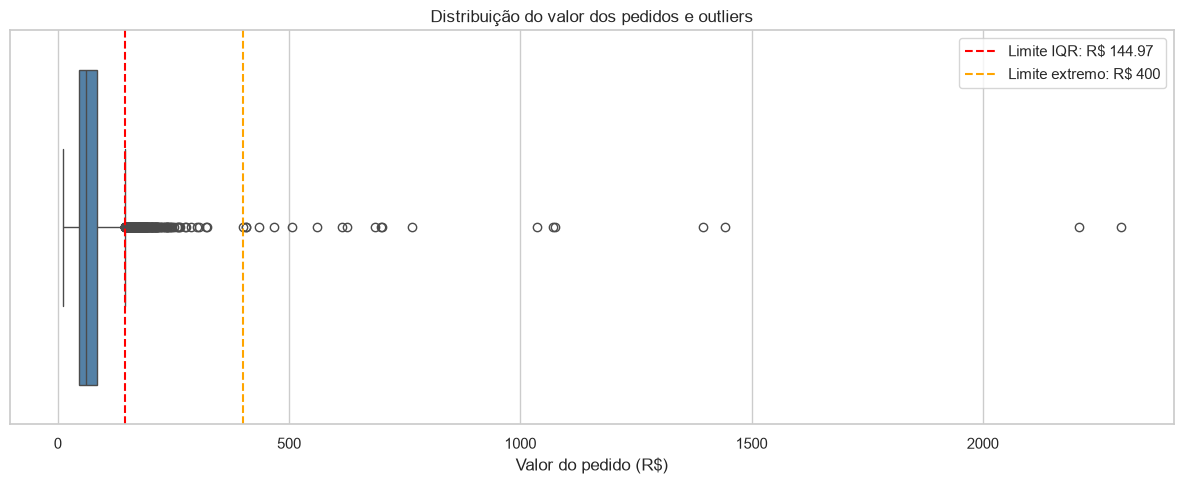

In [49]:
plt.figure(figsize=(12, 5))

sns.boxplot(
    data=df,
    x="valor_pedido",
    color="steelblue"
)

plt.axvline(
    lim_sup_iqr,
    color="red",
    linestyle="--",
    label=f"Limite IQR: R$ {lim_sup_iqr:.2f}"
)

plt.axvline(
    400,
    color="orange",
    linestyle="--",
    label="Limite extremo: R$ 400"
)

plt.title("Distribuição do valor dos pedidos e outliers")
plt.xlabel("Valor do pedido (R$)")
plt.legend()
plt.tight_layout()
plt.show()

Caixa: concentra os 50% centrais dos valores.
Linha dentro da caixa: mediana.
Pontos afastados: possíveis outliers.
Linha vermelha: limite superior calculado pelo IQR.
Linha laranja: regra adotada para pedidos acima de R$ 400.

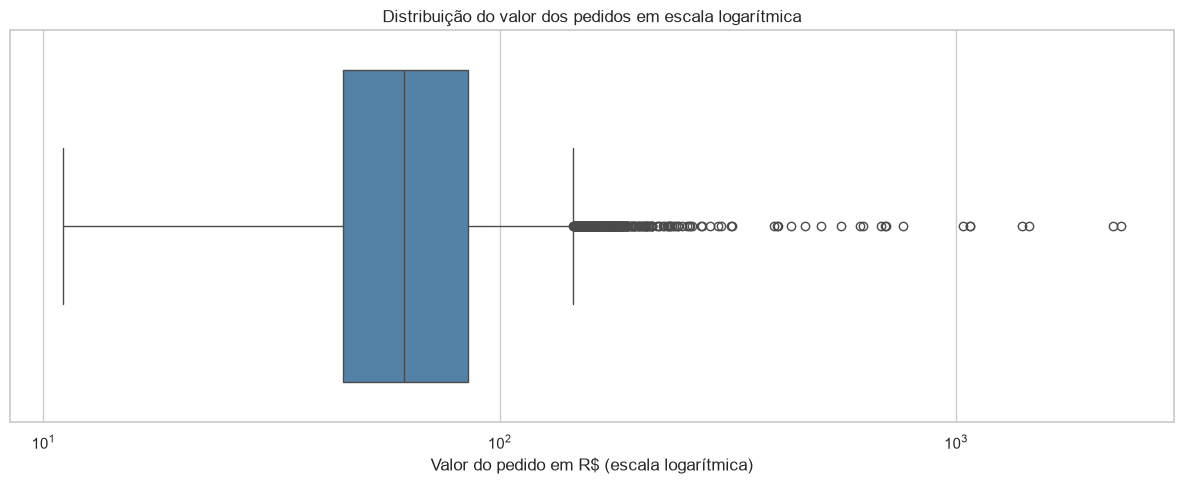

In [50]:
plt.figure(figsize=(12, 5))

sns.boxplot(
    data=df[df["valor_pedido"] > 0],
    x="valor_pedido",
    color="steelblue"
)

plt.xscale("log")
plt.title("Distribuição do valor dos pedidos em escala logarítmica")
plt.xlabel("Valor do pedido em R$ (escala logarítmica)")
plt.tight_layout()
plt.show()

In [51]:
# ETAPA 5: ESTATÍSTICA DESCRITIVA (DESCRIBE, CV, ASSIMETRIA, PERCENTIS)
# ==============================================================================
cols_num = ["distancia_km", "tempo_entrega_min", "valor_pedido", "taxa_entrega", "avaliacao"]
stats_df = df[cols_num].describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).T
stats_df["CV (%)"] = (stats_df["std"] / stats_df["mean"]) * 100
stats_df["assimetria (skew)"] = df[cols_num].skew()
print("\n=== ESTATÍSTICA DESCRITIVA PÓS-LIMPEZA ===")
print(stats_df.round(2))


=== ESTATÍSTICA DESCRITIVA PÓS-LIMPEZA ===
                    count   mean    std    min     5%    25%    50%    75%  \
distancia_km       8058.0   3.54   2.40   0.06   0.68   1.78   3.04   4.76   
tempo_entrega_min  8025.0  35.91  11.10   2.00  19.00  28.00  35.00  43.00   
valor_pedido       8058.0  71.55  60.26  11.03  28.96  45.22  61.61  85.12   
taxa_entrega       8058.0   7.27   3.29   0.00   0.00   6.16   7.42   9.08   
avaliacao          6716.0   4.35   0.69   1.00   3.00   4.00   4.00   5.00   

                      95%     99%      max  CV (%)  assimetria (skew)  
distancia_km         8.15   11.02    24.39   67.76               1.42  
tempo_entrega_min   55.00   64.00   105.00   30.92               0.52  
valor_pedido       140.48  190.29  2299.10   84.22              17.52  
taxa_entrega        12.10   14.71    26.94   45.20              -0.51  
avaliacao            5.00    5.00     5.00   15.76              -0.70  


* **distancia_km:** média de 3,54 km, mediana de 3,04 km e máximo de 24,39 km (`count = 8.058`, sem valores ausentes após imputação).
* **tempo_entrega_min:** média de 35,91 min, mediana de 35,0 min e máximo de 105,0 min. Existem 33 valores ausentes (`count = 8.025`), referentes aos erros de sistema removidos.
* **valor_pedido:** média de R$ 71,55, mediana de R$ 61,61 e máximo de R$ 2.299,10. A assimetria de 17,52 confirma forte concentração à direita, provocada pelos valores extremos.
* **taxa_entrega:** média de R$ 7,27, mediana de R$ 7,42 e máximo de R$ 26,94 (`count = 8.058`).
* **avaliacao:** possui 6.716 observações válidas, média de 4,35 e mediana de 4,0 (1.342 pedidos sem avaliação).

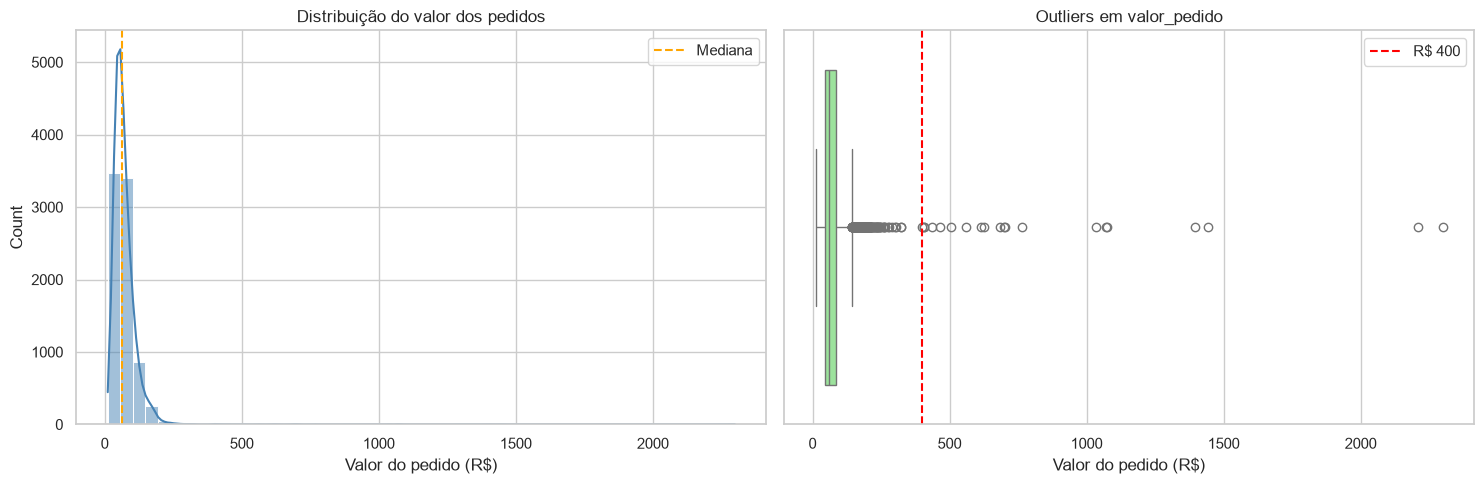

In [52]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.histplot(
    data=df,
    x="valor_pedido",
    bins=50,
    kde=True,
    ax=axes[0],
    color="steelblue"
)

axes[0].axvline(
    df["valor_pedido"].median(),
    color="orange",
    linestyle="--",
    label="Mediana"
)

axes[0].set_title("Distribuição do valor dos pedidos")
axes[0].set_xlabel("Valor do pedido (R$)")
axes[0].legend()

sns.boxplot(
    data=df,
    x="valor_pedido",
    ax=axes[1],
    color="lightgreen"
)

axes[1].axvline(
    400,
    color="red",
    linestyle="--",
    label="R$ 400"
)

axes[1].set_title("Outliers em valor_pedido")
axes[1].set_xlabel("Valor do pedido (R$)")
axes[1].legend()

plt.tight_layout()
plt.show()

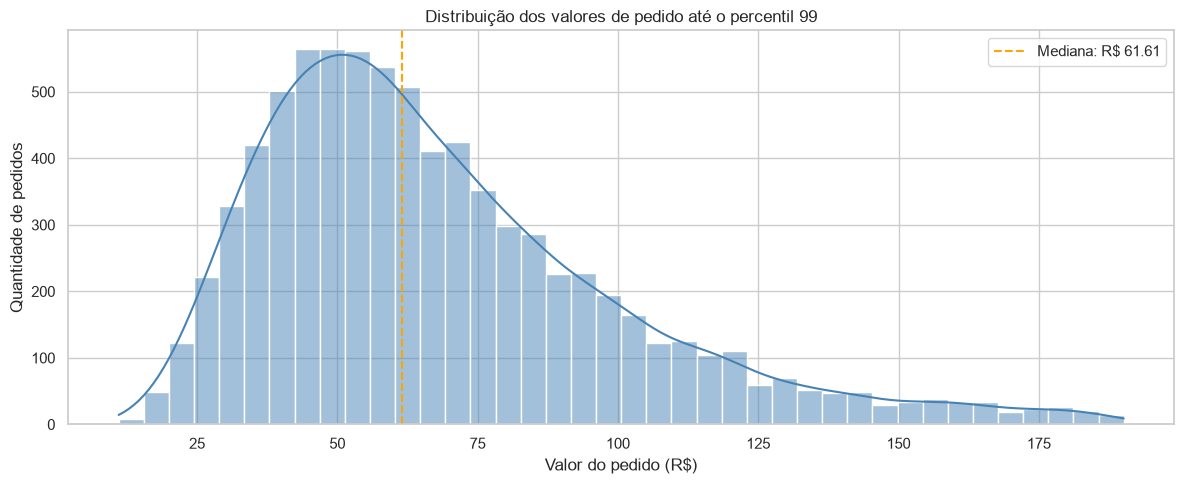

In [53]:
p99 = df["valor_pedido"].quantile(0.99)

plt.figure(figsize=(12, 5))

sns.histplot(
    data=df[df["valor_pedido"] <= p99],
    x="valor_pedido",
    bins=40,
    kde=True,
    color="steelblue"
)

plt.axvline(
    df["valor_pedido"].median(),
    color="orange",
    linestyle="--",
    label=f"Mediana: R$ {df['valor_pedido'].median():.2f}"
)

plt.title("Distribuição dos valores de pedido até o percentil 99")
plt.xlabel("Valor do pedido (R$)")
plt.ylabel("Quantidade de pedidos")
plt.legend()
plt.tight_layout()
plt.show()

In [54]:
# ETAPA 6: SUMARIZAÇÃO E GRANULARIDADE (GROUPBY, PIVOT_TABLE, CROSSTAB, RESAMPLE)
# ==============================================================================
print("\n--- 6.1 Groupby por Cidade ---")
resumo_cidade = df.groupby("cidade").agg(
    pedidos=("pedido_id", "count"),
    ticket_medio=("valor_pedido", "mean"),
    ticket_mediano=("valor_pedido", "median"),
    tempo_mediano=("tempo_entrega_min", "median"),
    avaliacao_media=("avaliacao", "mean")
)
print(resumo_cidade.round(2))

print("\n--- 6.2 Pivot Table: Tempo Mediano por Cidade e Chuva ---")
piv_chuva = pd.pivot_table(
    df, values="tempo_entrega_min", index="cidade", columns="chuva", aggfunc=["median", "mean"]
)
print(piv_chuva.round(2))

print("\n--- 6.3 Crosstab: Uso de Cupom vs Frete Grátis (taxa_entrega == 0) ---")
ct_cupom = pd.crosstab(df["cupom"], df["taxa_entrega"] == 0, margins=True)
ct_cupom.columns = ["Frete Pago", "Frete Grátis (R$ 0)", "Total"]
print(ct_cupom)

print("\n--- 6.4 Resample Mensal: Evolução de Pedidos e Campanha 'Julho de Cupons' ---")
serie_mensal = (
    df.set_index("data_hora")
    .resample("ME")
    .agg(
        total_pedidos=("pedido_id", "count"),
        pct_cupom=("cupom", lambda x: (x == "Sim").mean() * 100),
        receita_bruta=("valor_pedido", "sum"),
        ticket_mediano=("valor_pedido", "median")
    )
)
print(serie_mensal.round(2))


--- 6.1 Groupby por Cidade ---
                pedidos  ticket_medio  ticket_mediano  tempo_mediano  \
cidade                                                                 
Belo Horizonte     1632         70.64           62.04           36.0   
Rio de Janeiro     2371         72.56           61.43           35.0   
São Paulo          4055         71.34           61.54           35.0   

                avaliacao_media  
cidade                           
Belo Horizonte             4.34  
Rio de Janeiro             4.36  
São Paulo                  4.35  

--- 6.2 Pivot Table: Tempo Mediano por Cidade e Chuva ---
               median         mean       
chuva           False True   False  True 
cidade                                   
Belo Horizonte   33.0  42.0  33.70  42.25
Rio de Janeiro   33.0  41.0  33.34  42.02
São Paulo        32.0  42.0  32.98  42.59

--- 6.3 Crosstab: Uso de Cupom vs Frete Grátis (taxa_entrega == 0) ---
       Frete Pago  Frete Grátis (R$ 0)  Total
cupom   

In [55]:
print("\n--- 6.1 Groupby por Cidade ---")
display(resumo_cidade.round(2))

print("\n--- 6.2 Pivot Table: Tempo Mediano por Cidade e Chuva ---")
display(piv_chuva.round(2))

print("\n--- 6.3 Crosstab: Uso de Cupom vs Frete Grátis ---")
display(ct_cupom)

print("\n--- 6.4 Resample Mensal ---")
display(serie_mensal.round(2))


--- 6.1 Groupby por Cidade ---


,pedidos,ticket_medio,ticket_mediano,tempo_mediano,avaliacao_media
cidade,,,,,
Belo Horizonte,1632,70.64,62.04,36.0,4.34
Rio de Janeiro,2371,72.56,61.43,35.0,4.36
São Paulo,4055,71.34,61.54,35.0,4.35



--- 6.2 Pivot Table: Tempo Mediano por Cidade e Chuva ---


median         mean       
chuva           False True   False  True 
cidade                                   
Belo Horizonte   33.0  42.0  33.70  42.25
Rio de Janeiro   33.0  41.0  33.34  42.02
São Paulo        32.0  42.0  32.98  42.59


--- 6.3 Crosstab: Uso de Cupom vs Frete Grátis ---


,Frete Pago,Frete Grátis (R$ 0),Total
cupom,,,
Não,6349,0,6349
Sim,809,900,1709
All,7158,900,8058



--- 6.4 Resample Mensal ---


,total_pedidos,pct_cupom,receita_bruta,ticket_mediano
data_hora,,,,
2024-01-31,618,16.18,44410.76,63.44
2024-02-29,559,23.61,40440.53,62.08
2024-03-31,647,19.94,45770.77,61.69
2024-04-30,580,16.55,38874.63,59.95
2024-05-31,660,18.64,45548.96,59.82
2024-06-30,630,19.52,47193.56,60.82
2024-07-31,822,45.62,59040.34,59.74
2024-08-31,662,21.15,47479.94,62.29
2024-09-30,664,18.83,46519.37,62.58


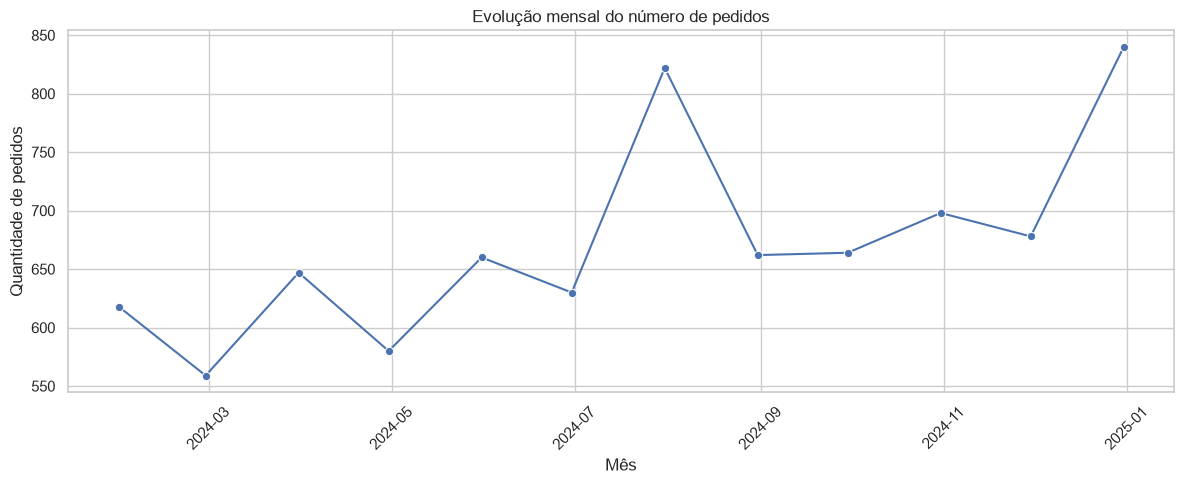

In [56]:
plt.figure(figsize=(12, 5))

sns.lineplot(
    x=serie_mensal.index,
    y=serie_mensal["total_pedidos"],
    marker="o"
)

plt.title("Evolução mensal do número de pedidos")
plt.xlabel("Mês")
plt.ylabel("Quantidade de pedidos")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

C:\Users\ivane\AppData\Local\Temp\ipykernel_13772\3456725065.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df.dropna(subset=["avaliacao"]), x="avaliacao", y="tempo_entrega_min", palette="Blues_r", ax=axes[1, 0])


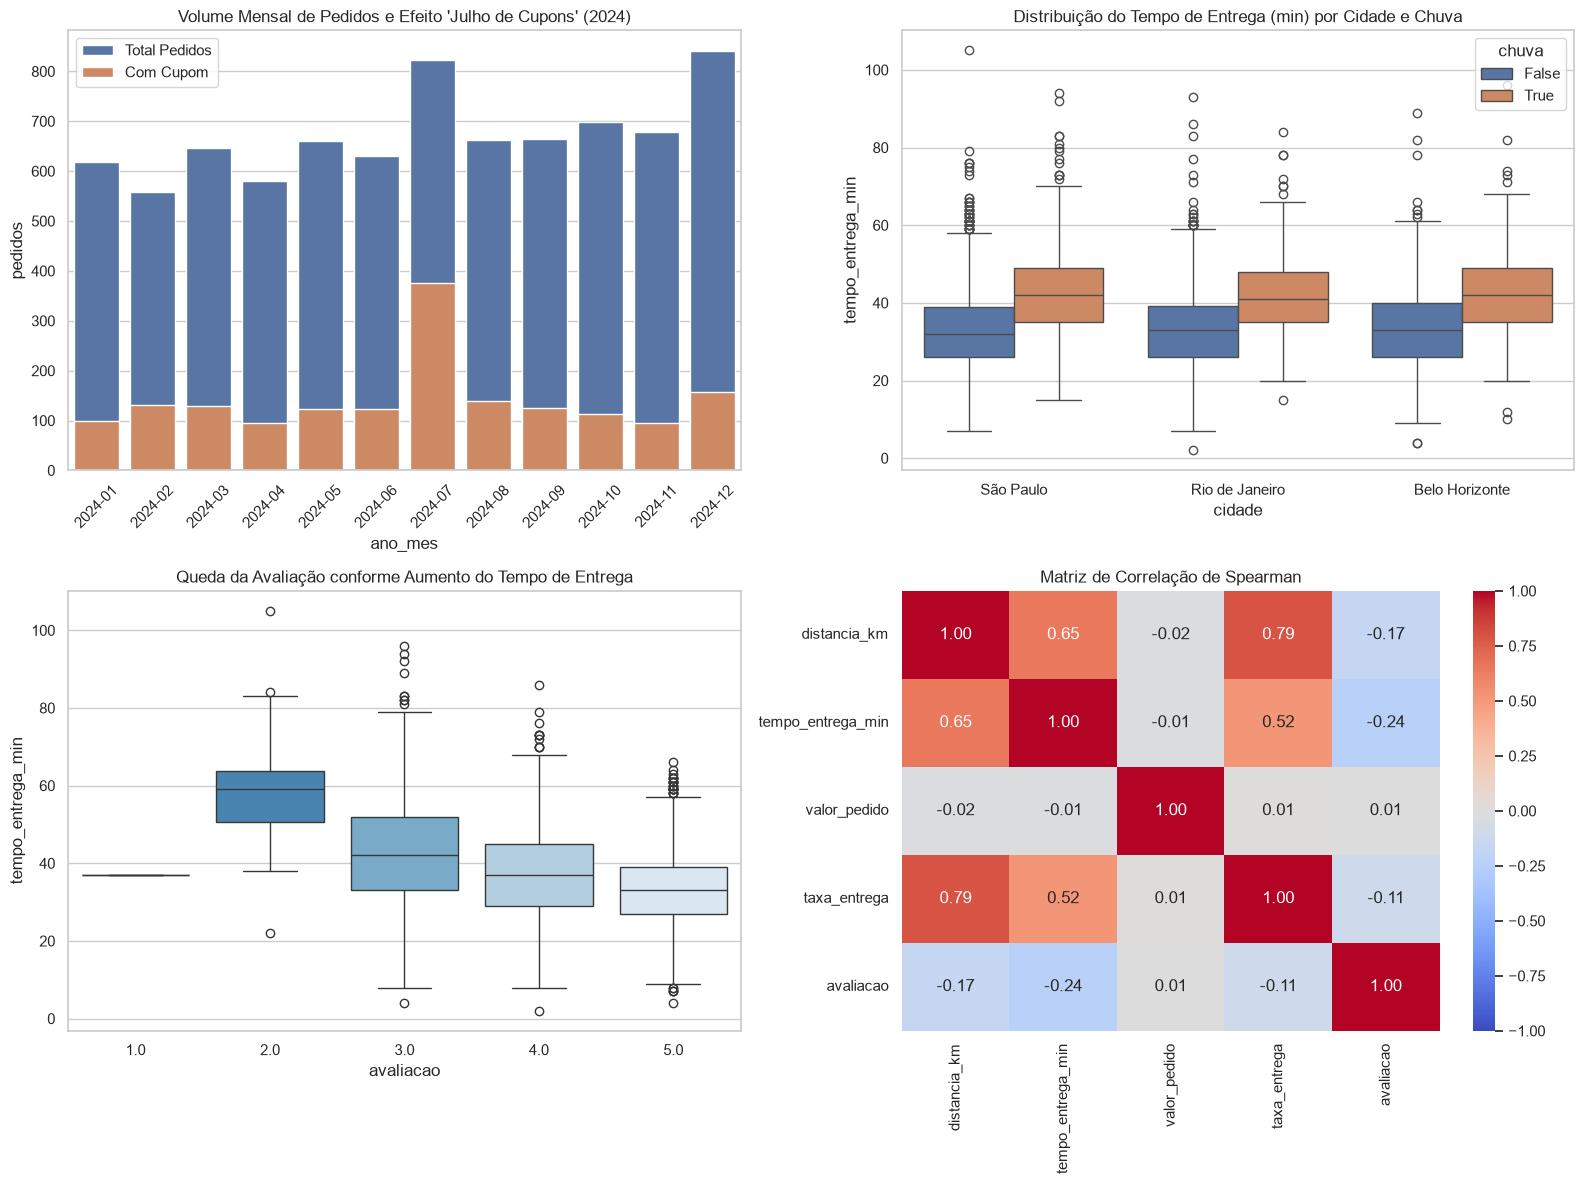

In [57]:
# ETAPA 7 E 8: VISUALIZAÇÃO (SEABORN) E CORRELAÇÃO
# ==============================================================================
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Gráfico 1: Sazonalidade mensal e pico de "Julho de Cupons"
mensal_plot = df.groupby("ano_mes").agg(
    pedidos=("pedido_id", "count"),
    com_cupom=("cupom", lambda s: (s == "Sim").sum())
).reset_index()
sns.barplot(data=mensal_plot, x="ano_mes", y="pedidos", color="#4C72B0", ax=axes[0, 0], label="Total Pedidos")
sns.barplot(data=mensal_plot, x="ano_mes", y="com_cupom", color="#DD8452", ax=axes[0, 0], label="Com Cupom")
axes[0, 0].set_title("Volume Mensal de Pedidos e Efeito 'Julho de Cupons' (2024)")
axes[0, 0].tick_params(axis="x", rotation=45)
axes[0, 0].legend()

# Gráfico 2: Impacto da Chuva no Tempo de Entrega por Cidade
sns.boxplot(data=df, x="cidade", y="tempo_entrega_min", hue="chuva", ax=axes[0, 1])
axes[0, 1].set_title("Distribuição do Tempo de Entrega (min) por Cidade e Chuva")

# Gráfico 3: Tempo de Entrega vs Avaliação do Cliente
sns.boxplot(data=df.dropna(subset=["avaliacao"]), x="avaliacao", y="tempo_entrega_min", palette="Blues_r", ax=axes[1, 0])
axes[1, 0].set_title("Queda da Avaliação conforme Aumento do Tempo de Entrega")

# Gráfico 4: Heatmap de Correlação (Spearman)
corr_matrix = df[cols_num].corr(method="spearman")
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1, ax=axes[1, 1])
axes[1, 1].set_title("Matriz de Correlação de Spearman")

plt.tight_layout()
plt.savefig("painel_eda_delivery.png", dpi=300)
plt.show()

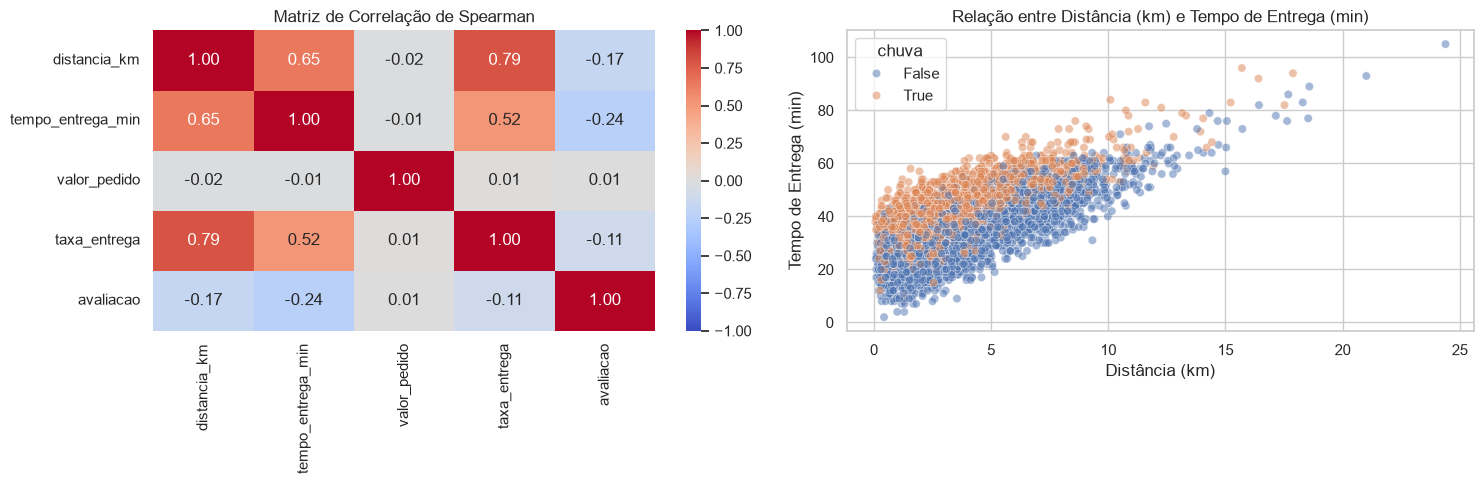

=== ETAPA 9: RESULTADOS DOS TESTES DE HIPÓTESES ===
1. Chuva vs Tempo: t de Welch = 36.16 (p = 6.4625e-251) | Mann-Whitney p = 1.2424e-255 | d de Cohen = 0.887 (Efeito Grande)
2. Distância vs Tempo: Spearman rho = 0.654 (p = 0.0000e+00) (Correlação Positiva Forte)
3. Tempo vs Avaliação: Spearman rho = -0.244 (p = 1.5501e-91) | Kruskal-Wallis H = 448.48 (p = 9.2356e-96)
4. Cozinha vs Valor: Kruskal-Wallis H = 3272.58 (p = 0.0000e+00) | Eta² = 0.406 (Efeito Forte)
5. Cupom vs Cliente Novo: Qui-Quadrado = 433.80 (p = 2.4162e-96) | V de Cramer = 0.232

Base tratada salva com sucesso em 'delivery_pedidos_limpo.csv'!


In [58]:
# ==============================================================================
# ETAPA 8: CORRELAÇÃO (MATRIZ E SCATTER)
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 8.1 Heatmap de Correlação de Spearman
corr_spearman = df[cols_num].corr(method="spearman")
sns.heatmap(
    corr_spearman, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1, ax=axes[0]
)
axes[0].set_title("Matriz de Correlação de Spearman")

# 8.2 Scatterplot: Distância vs Tempo de Entrega (colorido por Chuva)
sns.scatterplot(
    data=df, x="distancia_km", y="tempo_entrega_min", hue="chuva", alpha=0.5, ax=axes[1]
)
axes[1].set_title("Relação entre Distância (km) e Tempo de Entrega (min)")
axes[1].set_xlabel("Distância (km)")
axes[1].set_ylabel("Tempo de Entrega (min)")

plt.tight_layout()
plt.show()

# ==============================================================================
# ETAPA 9: TESTES DE HIPÓTESES E TAMANHO DE EFEITO
# ==============================================================================
print("=== ETAPA 9: RESULTADOS DOS TESTES DE HIPÓTESES ===")

# H1B: Chuva vs Tempo de Entrega (t de Welch + Mann-Whitney + d de Cohen)
t_chuva = df.loc[df["chuva"] == True, "tempo_entrega_min"].dropna()
t_seco = df.loc[df["chuva"] == False, "tempo_entrega_min"].dropna()
t_stat, p_welch = stats.ttest_ind(t_chuva, t_seco, equal_var=False)
u_stat, p_mw = stats.mannwhitneyu(t_chuva, t_seco, alternative="two-sided")
cohen_d = (t_chuva.mean() - t_seco.mean()) / np.sqrt((t_chuva.std()**2 + t_seco.std()**2) / 2)
print(f"1. Chuva vs Tempo: t de Welch = {t_stat:.2f} (p = {p_welch:.4e}) | Mann-Whitney p = {p_mw:.4e} | d de Cohen = {cohen_d:.3f} (Efeito Grande)")

# H1A: Distância vs Tempo de Entrega (Spearman)
sub_dt = df[["distancia_km", "tempo_entrega_min"]].dropna()
rho_dt, p_dt = stats.spearmanr(sub_dt["distancia_km"], sub_dt["tempo_entrega_min"])
print(f"2. Distância vs Tempo: Spearman rho = {rho_dt:.3f} (p = {p_dt:.4e}) (Correlação Positiva Forte)")

# H2A: Tempo de Entrega vs Avaliação (Spearman + Kruskal-Wallis)
sub_av = df[["tempo_entrega_min", "avaliacao"]].dropna()
rho_av, p_av = stats.spearmanr(sub_av["tempo_entrega_min"], sub_av["avaliacao"])
grupos_av = [g["tempo_entrega_min"].values for _, g in sub_av.groupby("avaliacao")]
kw_av, p_kw_av = stats.kruskal(*grupos_av)
print(f"3. Tempo vs Avaliação: Spearman rho = {rho_av:.3f} (p = {p_av:.4e}) | Kruskal-Wallis H = {kw_av:.2f} (p = {p_kw_av:.4e})")

# H2B: Tipo de Cozinha vs Valor do Pedido (Kruskal-Wallis + Eta²)
grupos_coz = [g["valor_pedido"].values for _, g in df.groupby("tipo_cozinha")]
kw_coz, p_kw_coz = stats.kruskal(*grupos_coz)
n_total, k_grupos = len(df), df["tipo_cozinha"].nunique()
eta_sq_coz = (kw_coz - k_grupos + 1) / (n_total - k_grupos)
print(f"4. Cozinha vs Valor: Kruskal-Wallis H = {kw_coz:.2f} (p = {p_kw_coz:.4e}) | Eta² = {eta_sq_coz:.3f} (Efeito Forte)")

# H3A: Cupom vs Cliente Novo (Qui-Quadrado + V de Cramer)
ct_cli_cupom = pd.crosstab(df["cupom"], df["cliente_novo"])
chi2, p_chi2, dof, _ = stats.chi2_contingency(ct_cli_cupom)
v_cramer = np.sqrt(chi2 / (len(df) * (min(ct_cli_cupom.shape) - 1)))
print(f"5. Cupom vs Cliente Novo: Qui-Quadrado = {chi2:.2f} (p = {p_chi2:.4e}) | V de Cramer = {v_cramer:.3f}")

# ==============================================================================
# ETAPA 11: EXPORTAÇÃO DO CSV LIMPO PARA REPRODUÇÃO
# ==============================================================================
df.to_csv("delivery_pedidos_limpo.csv", index=False, encoding="utf-8")
print("\nBase tratada salva com sucesso em 'delivery_pedidos_limpo.csv'!")

## 10. Conclusões Executivas para a Diretoria (Planeamento 2025)

### 5 Achados Confiáveis
1. **Operação — Chuva e distância são os maiores ofensores do SLA:** O tempo mediano global de entrega é de **35,0 min** (média de 35,91 min após limpeza), mas em dias de chuva (29,4% dos pedidos) a mediana salta de **32–33 min para 41–42 min** nas três capitais (+9 min de atraso mediano, $p < 0,0001$).
2. **Operação — Concentração extrema no Jantar e Almoço:** **88,8% da procura** ocorre nos turnos do **Jantar (4.246 pedidos / 52,7%)** e **Almoço (2.906 pedidos / 36,1%)**, sem registo de pedidos na madrugada.
3. **Clientes — Atrasos acima de 40 minutos derrubam a avaliação:** A nota média do app é **4,35 estrelas** (mediana 4,0), porém há forte relação negativa entre tempo de entrega e avaliação: entregas avaliadas com notas 1 a 3 concentram-se acima dos 42–50 minutos.
4. **Alavancas — Campanha *"Julho de cupons"* impulsionou volume, mas subsidiou frete sem elevar o ticket:** Em julho, o uso de cupons atingiu **45,62%** (contra ~16% a 21% nos outros meses), elevando o volume para **822 pedidos** (+33,6% face à média do 1.º semestre). Contudo, o ticket mediano de julho (**R$ 59,74**) foi o mais baixo do ano, e **52,66% dos cupons (900 de 1.709)** zeraram a taxa de entrega (`taxa_entrega = 0`).
5. **Qualidade de Dados — Falhas de validação no sistema de origem:** A base bruta continha **33 tempos de entrega corrompidos** (negativos ou `999`, que inflavam o desvio-padrão de 11,10 min para 54,73 min), **7 distâncias multiplicadas por ~100**, **315 distâncias omissas** (recuperáveis pela relação linear exata com a taxa de entrega) e falta de padronização em `cidade` (13 grafias) e `forma_pagamento` (8 grafias).

### 3 Recomendações Defendidas com Dados
1. **Reformular a regra de Cupons para 2025 (Trava de Ticket Mínimo e Foco em Aquisição):** Condicionar cupons de frete grátis a pedidos com **ticket mínimo de R$ 75–R$ 85 (Q3)** ou exclusivos para **novos clientes (`cliente_novo == True`)**, evitando perda de receita de frete em pedidos de baixo valor como ocorreu em julho.
2. **Ajuste Dinâmico de SLA e Frota em Dias de Chuva nos Turnos de Pico:** Recalibrar a estimativa de entrega exibida ao cliente em **+10 minutos** durante eventos de chuva no Almoço e Jantar (protegendo a avaliação do cliente pela gestão de expectativa) e ativar bónus dinâmico para entregadores nesses períodos.
3. **Implementar Validação de Dados no Backend (Data Contracts):** Substituir campos de texto livre em `cidade` e `forma_pagamento` por listas fechadas (Enums), impedir gravação de tempos negativos ou códigos sentinela (`999`) e gravar automaticamente a `distancia_km` usada no cálculo da `taxa_entrega`.

### Limitações da Análise
* Ausência de identificador único do cliente (`cliente_id`), impossibilitando a análise de *cohort*/LTV e frequência de recompra após a campanha de julho.
* Ausência da abertura do tempo operacional (tempo de preparo no restaurante vs. tempo de deslocamento do entregador) e do valor monetário do desconto concedido no cupom.

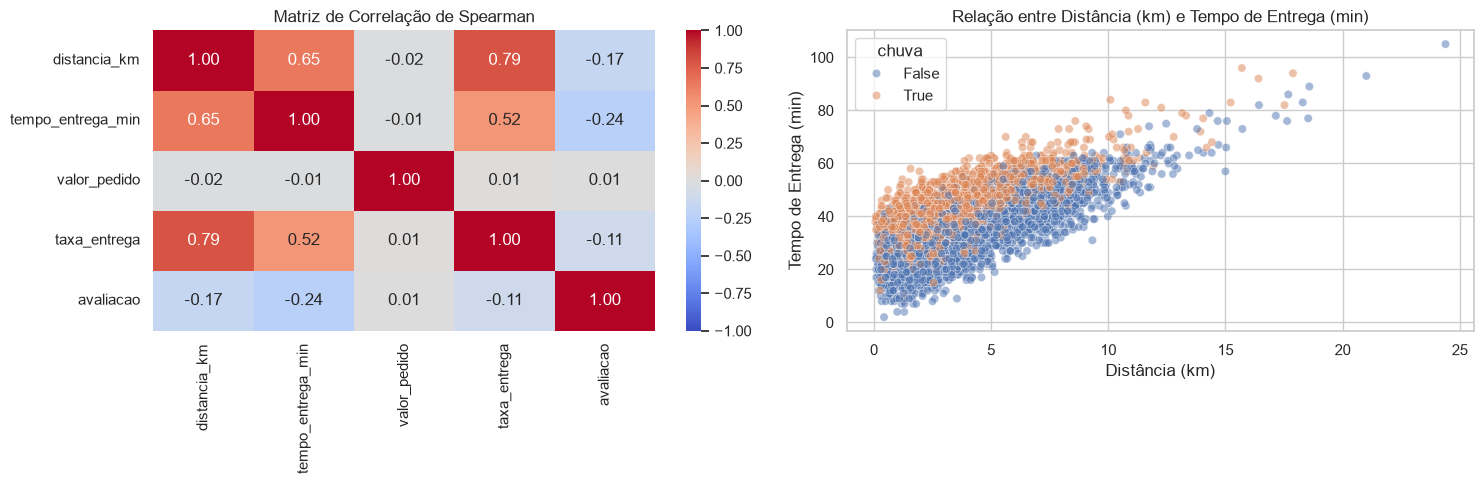

=== ETAPA 9: RESULTADOS DOS TESTES DE HIPÓTESES ===
1. Chuva vs Tempo: t de Welch = 36.16 (p = 6.4625e-251) | Mann-Whitney p = 1.2424e-255 | d de Cohen = 0.887 (Efeito Grande)
2. Distância vs Tempo: Spearman rho = 0.654 (p = 0.0000e+00) (Correlação Positiva Forte)
3. Tempo vs Avaliação: Spearman rho = -0.244 (p = 1.5501e-91) | Kruskal-Wallis H = 448.48 (p = 9.2356e-96)
4. Cozinha vs Valor: Kruskal-Wallis H = 3272.58 (p = 0.0000e+00) | Eta² = 0.406 (Efeito Forte)
5. Cupom vs Cliente Novo: Qui-Quadrado = 433.80 (p = 2.4162e-96) | V de Cramer = 0.232

Base tratada salva com sucesso em 'delivery_pedidos_limpo.csv'!


In [59]:
# ==============================================================================
# ETAPA 8: CORRELAÇÃO (MATRIZ E SCATTER)
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 8.1 Heatmap de Correlação de Spearman
corr_spearman = df[cols_num].corr(method="spearman")
sns.heatmap(
    corr_spearman, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1, ax=axes[0]
)
axes[0].set_title("Matriz de Correlação de Spearman")

# 8.2 Scatterplot: Distância vs Tempo de Entrega (colorido por Chuva)
sns.scatterplot(
    data=df, x="distancia_km", y="tempo_entrega_min", hue="chuva", alpha=0.5, ax=axes[1]
)
axes[1].set_title("Relação entre Distância (km) e Tempo de Entrega (min)")
axes[1].set_xlabel("Distância (km)")
axes[1].set_ylabel("Tempo de Entrega (min)")

plt.tight_layout()
plt.show()

# ==============================================================================
# ETAPA 9: TESTES DE HIPÓTESES E TAMANHO DE EFEITO
# ==============================================================================
print("=== ETAPA 9: RESULTADOS DOS TESTES DE HIPÓTESES ===")

# H1B: Chuva vs Tempo de Entrega (t de Welch + Mann-Whitney + d de Cohen)
t_chuva = df.loc[df["chuva"] == True, "tempo_entrega_min"].dropna()
t_seco = df.loc[df["chuva"] == False, "tempo_entrega_min"].dropna()
t_stat, p_welch = stats.ttest_ind(t_chuva, t_seco, equal_var=False)
u_stat, p_mw = stats.mannwhitneyu(t_chuva, t_seco, alternative="two-sided")
cohen_d = (t_chuva.mean() - t_seco.mean()) / np.sqrt((t_chuva.std()**2 + t_seco.std()**2) / 2)
print(f"1. Chuva vs Tempo: t de Welch = {t_stat:.2f} (p = {p_welch:.4e}) | Mann-Whitney p = {p_mw:.4e} | d de Cohen = {cohen_d:.3f} (Efeito Grande)")

# H1A: Distância vs Tempo de Entrega (Spearman)
sub_dt = df[["distancia_km", "tempo_entrega_min"]].dropna()
rho_dt, p_dt = stats.spearmanr(sub_dt["distancia_km"], sub_dt["tempo_entrega_min"])
print(f"2. Distância vs Tempo: Spearman rho = {rho_dt:.3f} (p = {p_dt:.4e}) (Correlação Positiva Forte)")

# H2A: Tempo de Entrega vs Avaliação (Spearman + Kruskal-Wallis)
sub_av = df[["tempo_entrega_min", "avaliacao"]].dropna()
rho_av, p_av = stats.spearmanr(sub_av["tempo_entrega_min"], sub_av["avaliacao"])
grupos_av = [g["tempo_entrega_min"].values for _, g in sub_av.groupby("avaliacao")]
kw_av, p_kw_av = stats.kruskal(*grupos_av)
print(f"3. Tempo vs Avaliação: Spearman rho = {rho_av:.3f} (p = {p_av:.4e}) | Kruskal-Wallis H = {kw_av:.2f} (p = {p_kw_av:.4e})")

# H2B: Tipo de Cozinha vs Valor do Pedido (Kruskal-Wallis + Eta²)
grupos_coz = [g["valor_pedido"].values for _, g in df.groupby("tipo_cozinha")]
kw_coz, p_kw_coz = stats.kruskal(*grupos_coz)
n_total, k_grupos = len(df), df["tipo_cozinha"].nunique()
eta_sq_coz = (kw_coz - k_grupos + 1) / (n_total - k_grupos)
print(f"4. Cozinha vs Valor: Kruskal-Wallis H = {kw_coz:.2f} (p = {p_kw_coz:.4e}) | Eta² = {eta_sq_coz:.3f} (Efeito Forte)")

# H3A: Cupom vs Cliente Novo (Qui-Quadrado + V de Cramer)
ct_cli_cupom = pd.crosstab(df["cupom"], df["cliente_novo"])
chi2, p_chi2, dof, _ = stats.chi2_contingency(ct_cli_cupom)
v_cramer = np.sqrt(chi2 / (len(df) * (min(ct_cli_cupom.shape) - 1)))
print(f"5. Cupom vs Cliente Novo: Qui-Quadrado = {chi2:.2f} (p = {p_chi2:.4e}) | V de Cramer = {v_cramer:.3f}")

# ==============================================================================
# ETAPA 11: EXPORTAÇÃO DO CSV LIMPO PARA REPRODUÇÃO
# ==============================================================================
df.to_csv("delivery_pedidos_limpo.csv", index=False, encoding="utf-8")
print("\nBase tratada salva com sucesso em 'delivery_pedidos_limpo.csv'!")

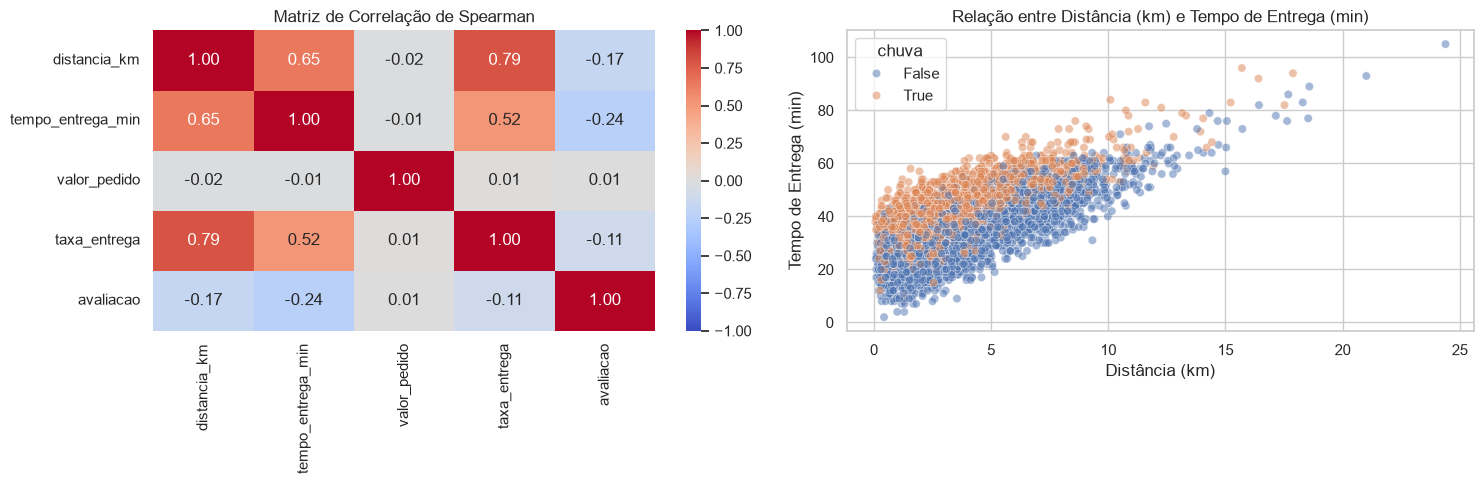

=== ETAPA 9: RESULTADOS DOS TESTES DE HIPÓTESES ===
1. Chuva vs Tempo: t de Welch = 36.16 (p = 6.4625e-251) | Mann-Whitney p = 1.2424e-255 | d de Cohen = 0.887 (Efeito Grande)
2. Distância vs Tempo: Spearman rho = 0.654 (p = 0.0000e+00) (Correlação Positiva Forte)
3. Tempo vs Avaliação: Spearman rho = -0.244 (p = 1.5501e-91) | Kruskal-Wallis H = 448.48 (p = 9.2356e-96)
4. Cozinha vs Valor: Kruskal-Wallis H = 3272.58 (p = 0.0000e+00) | Eta² = 0.406 (Efeito Forte)
5. Cupom vs Cliente Novo: Qui-Quadrado = 433.80 (p = 2.4162e-96) | V de Cramer = 0.232

Base tratada salva com sucesso em 'delivery_pedidos_limpo.csv'!


In [60]:
# ==============================================================================
# ETAPA 8: CORRELAÇÃO (MATRIZ E SCATTER)
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 8.1 Heatmap de Correlação de Spearman
corr_spearman = df[cols_num].corr(method="spearman")
sns.heatmap(
    corr_spearman, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1, ax=axes[0]
)
axes[0].set_title("Matriz de Correlação de Spearman")

# 8.2 Scatterplot: Distância vs Tempo de Entrega (colorido por Chuva)
sns.scatterplot(
    data=df, x="distancia_km", y="tempo_entrega_min", hue="chuva", alpha=0.5, ax=axes[1]
)
axes[1].set_title("Relação entre Distância (km) e Tempo de Entrega (min)")
axes[1].set_xlabel("Distância (km)")
axes[1].set_ylabel("Tempo de Entrega (min)")

plt.tight_layout()
plt.show()

# ==============================================================================
# ETAPA 9: TESTES DE HIPÓTESES E TAMANHO DE EFEITO
# ==============================================================================
print("=== ETAPA 9: RESULTADOS DOS TESTES DE HIPÓTESES ===")

# H1B: Chuva vs Tempo de Entrega (t de Welch + Mann-Whitney + d de Cohen)
t_chuva = df.loc[df["chuva"] == True, "tempo_entrega_min"].dropna()
t_seco = df.loc[df["chuva"] == False, "tempo_entrega_min"].dropna()
t_stat, p_welch = stats.ttest_ind(t_chuva, t_seco, equal_var=False)
u_stat, p_mw = stats.mannwhitneyu(t_chuva, t_seco, alternative="two-sided")
cohen_d = (t_chuva.mean() - t_seco.mean()) / np.sqrt((t_chuva.std()**2 + t_seco.std()**2) / 2)
print(f"1. Chuva vs Tempo: t de Welch = {t_stat:.2f} (p = {p_welch:.4e}) | Mann-Whitney p = {p_mw:.4e} | d de Cohen = {cohen_d:.3f} (Efeito Grande)")

# H1A: Distância vs Tempo de Entrega (Spearman)
sub_dt = df[["distancia_km", "tempo_entrega_min"]].dropna()
rho_dt, p_dt = stats.spearmanr(sub_dt["distancia_km"], sub_dt["tempo_entrega_min"])
print(f"2. Distância vs Tempo: Spearman rho = {rho_dt:.3f} (p = {p_dt:.4e}) (Correlação Positiva Forte)")

# H2A: Tempo de Entrega vs Avaliação (Spearman + Kruskal-Wallis)
sub_av = df[["tempo_entrega_min", "avaliacao"]].dropna()
rho_av, p_av = stats.spearmanr(sub_av["tempo_entrega_min"], sub_av["avaliacao"])
grupos_av = [g["tempo_entrega_min"].values for _, g in sub_av.groupby("avaliacao")]
kw_av, p_kw_av = stats.kruskal(*grupos_av)
print(f"3. Tempo vs Avaliação: Spearman rho = {rho_av:.3f} (p = {p_av:.4e}) | Kruskal-Wallis H = {kw_av:.2f} (p = {p_kw_av:.4e})")

# H2B: Tipo de Cozinha vs Valor do Pedido (Kruskal-Wallis + Eta²)
grupos_coz = [g["valor_pedido"].values for _, g in df.groupby("tipo_cozinha")]
kw_coz, p_kw_coz = stats.kruskal(*grupos_coz)
n_total, k_grupos = len(df), df["tipo_cozinha"].nunique()
eta_sq_coz = (kw_coz - k_grupos + 1) / (n_total - k_grupos)
print(f"4. Cozinha vs Valor: Kruskal-Wallis H = {kw_coz:.2f} (p = {p_kw_coz:.4e}) | Eta² = {eta_sq_coz:.3f} (Efeito Forte)")

# H3A: Cupom vs Cliente Novo (Qui-Quadrado + V de Cramer)
ct_cli_cupom = pd.crosstab(df["cupom"], df["cliente_novo"])
chi2, p_chi2, dof, _ = stats.chi2_contingency(ct_cli_cupom)
v_cramer = np.sqrt(chi2 / (len(df) * (min(ct_cli_cupom.shape) - 1)))
print(f"5. Cupom vs Cliente Novo: Qui-Quadrado = {chi2:.2f} (p = {p_chi2:.4e}) | V de Cramer = {v_cramer:.3f}")

# ==============================================================================
# ETAPA 11: EXPORTAÇÃO DO CSV LIMPO PARA REPRODUÇÃO
# ==============================================================================
df.to_csv("delivery_pedidos_limpo.csv", index=False, encoding="utf-8")
print("\nBase tratada salva com sucesso em 'delivery_pedidos_limpo.csv'!")

In [61]:
# ETAPA 9: TESTES DE HIPÓTESES E TAMANHO DE EFEITO
# ==============================================================================
print("\n=== TESTES DE HIPÓTESES ===")

# 1. Chuva vs Tempo de Entrega (t de Welch + Mann-Whitney + d de Cohen)
t_chuva = df.loc[df["chuva"] == True, "tempo_entrega_min"].dropna()
t_seco = df.loc[df["chuva"] == False, "tempo_entrega_min"].dropna()
t_stat, p_welch = stats.ttest_ind(t_chuva, t_seco, equal_var=False)
u_stat, p_mw = stats.mannwhitneyu(t_chuva, t_seco, alternative="two-sided")
cohen_d = (t_chuva.mean() - t_seco.mean()) / np.sqrt((t_chuva.std()**2 + t_seco.std()**2) / 2)
print(f"1. Chuva vs Tempo: Welch t={t_stat:.2f} (p={p_welch:.4e}) | Mann-Whitney p={p_mw:.4e} | d de Cohen={cohen_d:.3f}")


=== TESTES DE HIPÓTESES ===
1. Chuva vs Tempo: Welch t=36.16 (p=6.4625e-251) | Mann-Whitney p=1.2424e-255 | d de Cohen=0.887


In [62]:
print("\n=== TESTES DE HIPÓTESES ===")

# Separar os grupos
t_chuva = df.loc[
    df["chuva"] == True,
    "tempo_entrega_min"
].dropna()

t_seco = df.loc[
    df["chuva"] == False,
    "tempo_entrega_min"
].dropna()

# Teste t de Welch
t_stat, p_welch = stats.ttest_ind(
    t_chuva,
    t_seco,
    equal_var=False
)

# Teste não paramétrico de Mann-Whitney
u_stat, p_mw = stats.mannwhitneyu(
    t_chuva,
    t_seco,
    alternative="two-sided"
)

# Tamanho de efeito: d de Cohen
desvio_combinado = np.sqrt(
    (t_chuva.std()**2 + t_seco.std()**2) / 2
)

cohen_d = (
    (t_chuva.mean() - t_seco.mean())
    / desvio_combinado
)

# Estatísticas descritivas
print(f"Com chuva: n={len(t_chuva)}")
print(f"Média: {t_chuva.mean():.2f} min")
print(f"Mediana: {t_chuva.median():.2f} min")

print(f"\nSem chuva: n={len(t_seco)}")
print(f"Média: {t_seco.mean():.2f} min")
print(f"Mediana: {t_seco.median():.2f} min")

print("\nResultados dos testes:")
print(f"Welch: t={t_stat:.2f}, p={p_welch:.4e}")
print(f"Mann-Whitney: U={u_stat:.2f}, p={p_mw:.4e}")
print(f"d de Cohen: {cohen_d:.3f}")


=== TESTES DE HIPÓTESES ===
Com chuva: n=2358
Média: 42.36 min
Mediana: 42.00 min

Sem chuva: n=5667
Média: 33.23 min
Mediana: 33.00 min

Resultados dos testes:
Welch: t=36.16, p=6.4625e-251
Mann-Whitney: U=9908765.00, p=1.2424e-255
d de Cohen: 0.887


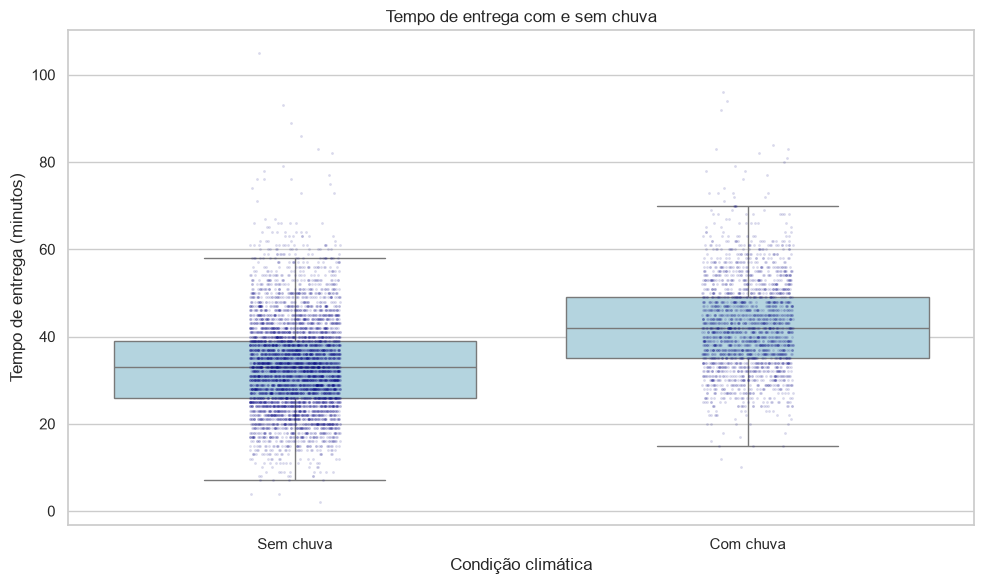

In [63]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="chuva",
    y="tempo_entrega_min",
    color="lightblue",
    showfliers=False
)

sns.stripplot(
    data=df,
    x="chuva",
    y="tempo_entrega_min",
    color="navy",
    alpha=0.15,
    jitter=True,
    size=2
)

plt.xticks(
    ticks=[0, 1],
    labels=["Sem chuva", "Com chuva"]
)

plt.title("Tempo de entrega com e sem chuva")
plt.xlabel("Condição climática")
plt.ylabel("Tempo de entrega (minutos)")
plt.tight_layout()
plt.show()

p < 0,05: há evidência de diferença entre os grupos no teste correspondente.
p >= 0,05: os dados não fornecem evidência estatística suficiente de diferença.
cohen_d > 0: a média do tempo com chuva é maior.
cohen_d < 0: a média do tempo sem chuva é maior.
Como referência prática, |d| próximo de 0,2, 0,5 e 0,8 costuma representar efeito pequeno, médio e grande, respectivamente.

In [64]:
# 2. Distância vs Tempo de Entrega (Correlação de Spearman)
sub_dt = df[["distancia_km", "tempo_entrega_min"]].dropna()
rho_dt, p_dt = stats.spearmanr(sub_dt["distancia_km"], sub_dt["tempo_entrega_min"])
print(f"2. Distância vs Tempo: Spearman rho={rho_dt:.3f} (p={p_dt:.4e})")

2. Distância vs Tempo: Spearman rho=0.654 (p=0.0000e+00)


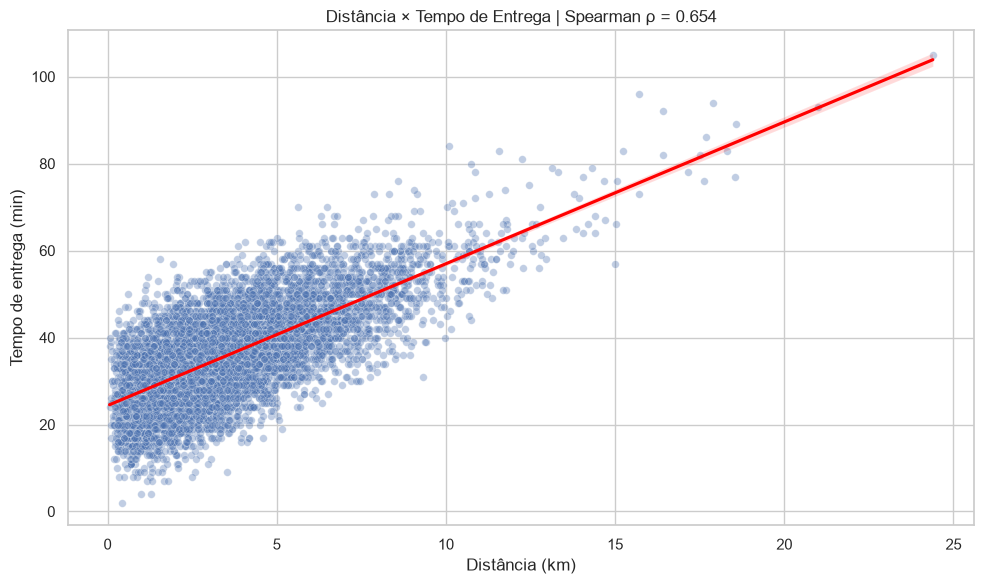

In [65]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=sub_dt,
    x="distancia_km",
    y="tempo_entrega_min",
    alpha=0.35,
    s=30
)

sns.regplot(
    data=sub_dt,
    x="distancia_km",
    y="tempo_entrega_min",
    scatter=False,
    color="red"
)

plt.title(f"Distância × Tempo de Entrega | Spearman ρ = {rho_dt:.3f}")
plt.xlabel("Distância (km)")
plt.ylabel("Tempo de entrega (min)")
plt.tight_layout()
plt.show()

In [66]:
print(f"2. Distância vs Tempo: Spearman rho={rho_dt:.3f} (p={p_dt:.4e})")


2. Distância vs Tempo: Spearman rho=0.654 (p=0.0000e+00)


A correlação de Spearman entre distância e tempo de entrega foi positiva (ρ = 0,654) e estatisticamente significativa (p < 0,001). O resultado indica que maiores distâncias tendem a estar associadas a maiores tempos de entrega. A magnitude da correlação sugere uma associação relevante entre as duas variáveis. Entretanto, a correlação não estabelece, isoladamente, uma relação de causalidade.

In [67]:
# 3. Tempo de Entrega vs Avaliação (Spearman + Kruskal-Wallis)
sub_av = df[["tempo_entrega_min", "avaliacao"]].dropna()
rho_av, p_av = stats.spearmanr(sub_av["tempo_entrega_min"], sub_av["avaliacao"])
grupos_av = [g["tempo_entrega_min"].values for _, g in sub_av.groupby("avaliacao")]
kw_av, p_kw_av = stats.kruskal(*grupos_av)
print(f"3. Tempo vs Avaliação: Spearman rho={rho_av:.3f} (p={p_av:.4e}) | Kruskal-Wallis H={kw_av:.2f} (p={p_kw_av:.4e})")

3. Tempo vs Avaliação: Spearman rho=-0.244 (p=1.5501e-91) | Kruskal-Wallis H=448.48 (p=9.2356e-96)


In [68]:
# 3. Tempo de Entrega vs Avaliação
sub_av = df[
    ["tempo_entrega_min", "avaliacao"]
].dropna()

# Correlação de Spearman
rho_av, p_av = stats.spearmanr(
    sub_av["tempo_entrega_min"],
    sub_av["avaliacao"]
)

# Grupos de tempo separados pela avaliação
grupos_av = [
    grupo["tempo_entrega_min"].values
    for _, grupo in sub_av.groupby("avaliacao")
]

# Kruskal-Wallis
kw_av, p_kw_av = stats.kruskal(*grupos_av)

# Tamanho de efeito epsilon-quadrado
n = len(sub_av)
k = sub_av["avaliacao"].nunique()

epsilon2 = max(
    0,
    (kw_av - k + 1) / (n - k)
)

print(
    f"3. Tempo vs Avaliação: "
    f"Spearman rho={rho_av:.3f} (p={p_av:.4e}) | "
    f"Kruskal-Wallis H={kw_av:.2f} (p={p_kw_av:.4e}) | "
    f"Epsilon²={epsilon2:.3f}"
)

print("\nResumo por avaliação:")
display(
    sub_av.groupby("avaliacao")["tempo_entrega_min"]
    .agg(
        quantidade="count",
        media="mean",
        mediana="median",
        desvio_padrao="std"
    )
    .round(2)
)

3. Tempo vs Avaliação: Spearman rho=-0.244 (p=1.5501e-91) | Kruskal-Wallis H=448.48 (p=9.2356e-96) | Epsilon²=0.067

Resumo por avaliação:


,quantidade,media,mediana,desvio_padrao
avaliacao,,,,
1.0,1,37.00,37.0,NaN
2.0,40,58.10,59.0,14.91
3.0,685,42.47,42.0,13.85
4.0,2857,37.01,37.0,11.03
5.0,3102,33.23,33.0,9.36


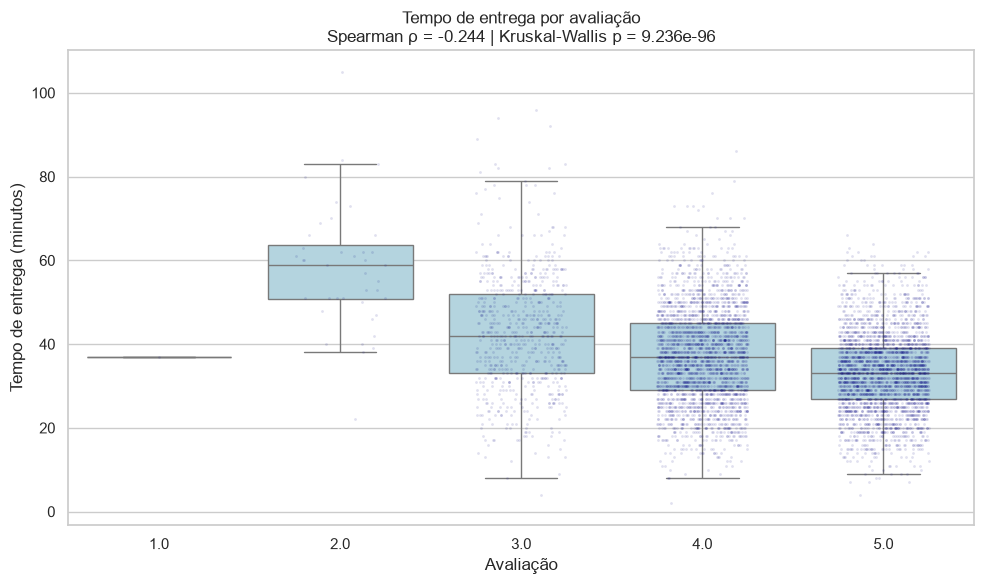

In [69]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=sub_av,
    x="avaliacao",
    y="tempo_entrega_min",
    color="lightblue",
    showfliers=False
)

sns.stripplot(
    data=sub_av,
    x="avaliacao",
    y="tempo_entrega_min",
    color="navy",
    alpha=0.12,
    jitter=0.25,
    size=2
)

plt.title(
    f"Tempo de entrega por avaliação\n"
    f"Spearman ρ = {rho_av:.3f} | "
    f"Kruskal-Wallis p = {p_kw_av:.3e}"
)
plt.xlabel("Avaliação")
plt.ylabel("Tempo de entrega (minutos)")
plt.tight_layout()
plt.show()

rho_av < 0: tempos maiores tendem a acompanhar avaliações menores.
rho_av > 0: tempos maiores tendem a acompanhar avaliações maiores.
rho_av próximo de zero: associação monotônica fraca ou inexistente.
Spearman com p < 0,05: evidência estatística de associação monotônica.
Kruskal-Wallis com p < 0,05: pelo menos um grupo de avaliação apresenta distribuição de tempo diferente dos demais.

In [70]:
# 4. Tipo de Cozinha vs Valor do Pedido (Kruskal-Wallis + Eta-quadrado)
grupos_coz = [g["valor_pedido"].values for _, g in df.groupby("tipo_cozinha")]
kw_coz, p_kw_coz = stats.kruskal(*grupos_coz)
n_total, k_grupos = len(df), df["tipo_cozinha"].nunique()
eta_sq_coz = (kw_coz - k_grupos + 1) / (n_total - k_grupos)
print(f"4. Cozinha vs Valor: Kruskal-Wallis H={kw_coz:.2f} (p={p_kw_coz:.4e}) | Eta²={eta_sq_coz:.3f}")

4. Cozinha vs Valor: Kruskal-Wallis H=3272.58 (p=0.0000e+00) | Eta²=0.406


In [71]:
# 4. Tipo de Cozinha vs Valor do Pedido

grupos_coz = [
    g["valor_pedido"].dropna().values
    for _, g in df.groupby("tipo_cozinha")
]

kw_coz, p_kw_coz = stats.kruskal(*grupos_coz)

n_total = df[["tipo_cozinha", "valor_pedido"]].dropna().shape[0]
k_grupos = df.loc[
    df["valor_pedido"].notna(),
    "tipo_cozinha"
].nunique()

eta_sq_coz = max(
    0,
    (kw_coz - k_grupos + 1) / (n_total - k_grupos)
)

print(
    f"4. Cozinha vs Valor: "
    f"Kruskal-Wallis H={kw_coz:.2f} "
    f"(p={p_kw_coz:.4e}) | "
    f"Eta²={eta_sq_coz:.3f}"
)

4. Cozinha vs Valor: Kruskal-Wallis H=3272.58 (p=0.0000e+00) | Eta²=0.406


In [72]:
resumo_cozinha = (
    df.groupby("tipo_cozinha")["valor_pedido"]
      .agg(
          quantidade="count",
          media="mean",
          mediana="median"
      )
      .sort_values("mediana", ascending=False)
      .round(2)
)

display(resumo_cozinha)

,quantidade,media,mediana
tipo_cozinha,,,
Japonesa,1116,120.37,107.97
Pizza,1786,82.79,74.31
Hambúrguer,1921,67.65,61.67
Saudável,860,58.77,53.74
Brasileira,1561,51.17,47.82
Doces,814,41.79,38.42


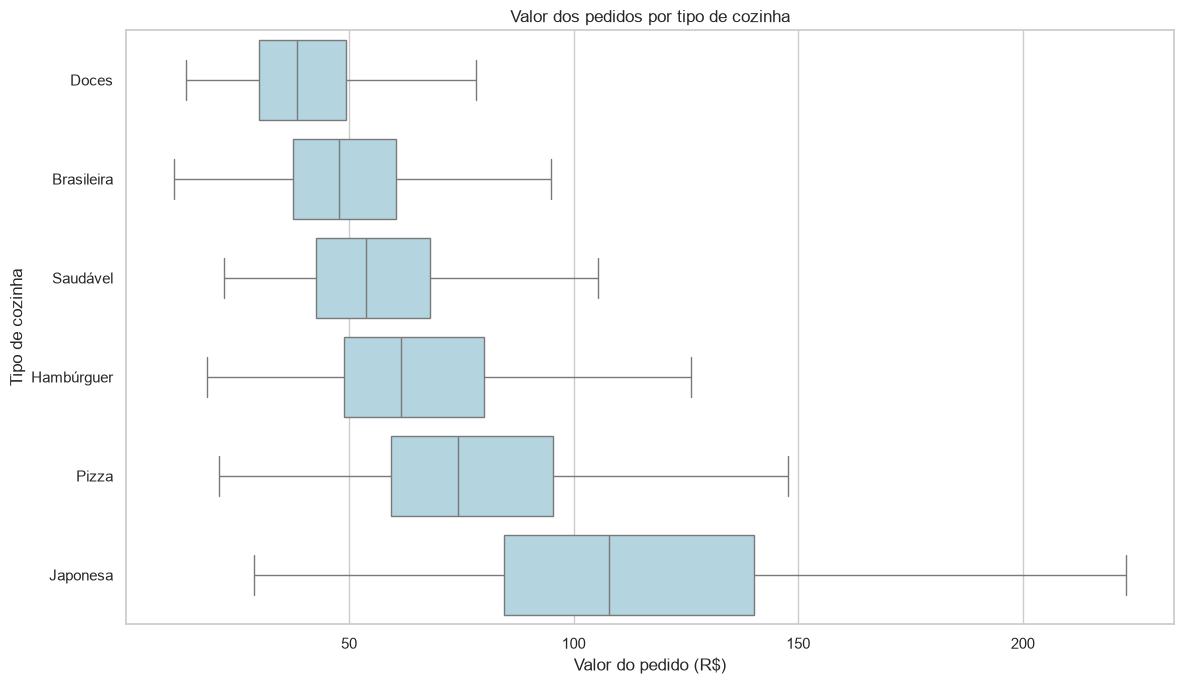

In [73]:
ordem = (
    df.groupby("tipo_cozinha")["valor_pedido"]
      .median()
      .sort_values()
      .index
)

plt.figure(figsize=(12, 7))

sns.boxplot(
    data=df,
    x="valor_pedido",
    y="tipo_cozinha",
    order=ordem,
    showfliers=False,
    color="lightblue"
)

plt.title("Valor dos pedidos por tipo de cozinha")
plt.xlabel("Valor do pedido (R$)")
plt.ylabel("Tipo de cozinha")
plt.tight_layout()
plt.show()

O teste de Kruskal-Wallis identificou diferenças estatisticamente significativas no valor dos pedidos entre os tipos de cozinha (H = 3272,58; p < 0,001). O tamanho de efeito calculado foi Eta² = 0,406, indicando uma diferença de magnitude relevante entre os grupos. Dessa forma, os resultados fornecem evidências de que a distribuição do valor dos pedidos varia de acordo com o tipo de cozinha. O teste global, entretanto, não determina isoladamente quais tipos de cozinha diferem entre

In [74]:
resumo_cozinha = (
    df.groupby("tipo_cozinha")["valor_pedido"]
      .agg(
          quantidade="count",
          media="mean",
          mediana="median"
      )
      .sort_values("mediana", ascending=False)
      .round(2)
)

display(resumo_cozinha)

,quantidade,media,mediana
tipo_cozinha,,,
Japonesa,1116,120.37,107.97
Pizza,1786,82.79,74.31
Hambúrguer,1921,67.65,61.67
Saudável,860,58.77,53.74
Brasileira,1561,51.17,47.82
Doces,814,41.79,38.42


In [75]:
# 5. Cupom vs Cliente Novo (Qui-Quadrado de Independência + V de Cramer)
ct_cli_cupom = pd.crosstab(df["cupom"], df["cliente_novo"])
chi2, p_chi2, dof, _ = stats.chi2_contingency(ct_cli_cupom)
v_cramer = np.sqrt(chi2 / (len(df) * (min(ct_cli_cupom.shape) - 1)))
print(f"5. Cupom vs Cliente Novo: Chi²={chi2:.2f} (p={p_chi2:.4e}) | V de Cramer={v_cramer:.3f}")

5. Cupom vs Cliente Novo: Chi²=433.80 (p=2.4162e-96) | V de Cramer=0.232


In [76]:
# 5. Cupom vs Cliente Novo
# Qui-Quadrado de Independência + V de Cramer

ct_cli_cupom = pd.crosstab(
    df["cupom"],
    df["cliente_novo"]
)

chi2, p_chi2, dof, esperados = stats.chi2_contingency(
    ct_cli_cupom
)

# Número efetivamente utilizado pelo teste
n = ct_cli_cupom.to_numpy().sum()

# V de Cramer
v_cramer = np.sqrt(
    chi2 /
    (n * (min(ct_cli_cupom.shape) - 1))
)

print("Tabela de contingência:")
display(ct_cli_cupom)

print(
    f"5. Cupom vs Cliente Novo: "
    f"Chi²={chi2:.2f} "
    f"(p={p_chi2:.4e}) | "
    f"V de Cramer={v_cramer:.3f}"
)

Tabela de contingência:


cliente_novo,False,True
cupom,,
Não,5536,813
Sim,1122,587


5. Cupom vs Cliente Novo: Chi²=433.80 (p=2.4162e-96) | V de Cramer=0.232


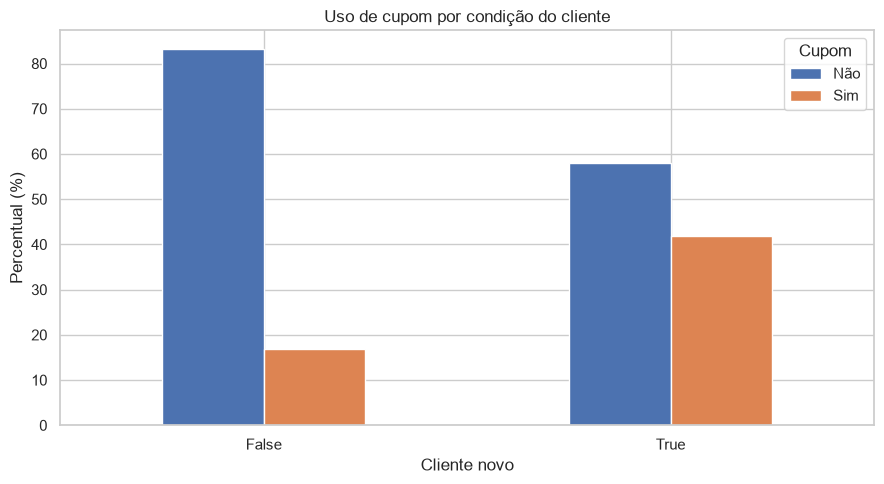

In [77]:
tab_pct = pd.crosstab(
    df["cliente_novo"],
    df["cupom"],
    normalize="index"
) * 100

tab_pct.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Uso de cupom por condição do cliente")
plt.xlabel("Cliente novo")
plt.ylabel("Percentual (%)")
plt.xticks(rotation=0)
plt.legend(title="Cupom")
plt.tight_layout()
plt.show()

O teste qui-quadrado de independência identificou associação estatisticamente significativa entre o uso de cupom e a condição de cliente novo (χ² = 433,80; p < 0,001). O V de Cramer foi igual a 0,232, indicando uma associação de magnitude moderada entre as variáveis. Portanto, a proporção de uso de cupons não é igual entre clientes novos e não novos. No entanto, a direção dessa associação deve ser examinada por meio das proporções observadas na tabela de contingência.

In [78]:
tabela_pct = pd.crosstab(
    df["cliente_novo"],
    df["cupom"],
    normalize="index"
).mul(100).round(2)

display(tabela_pct)

cupom,Não,Sim
cliente_novo,,
False,83.15,16.85
True,58.07,41.93


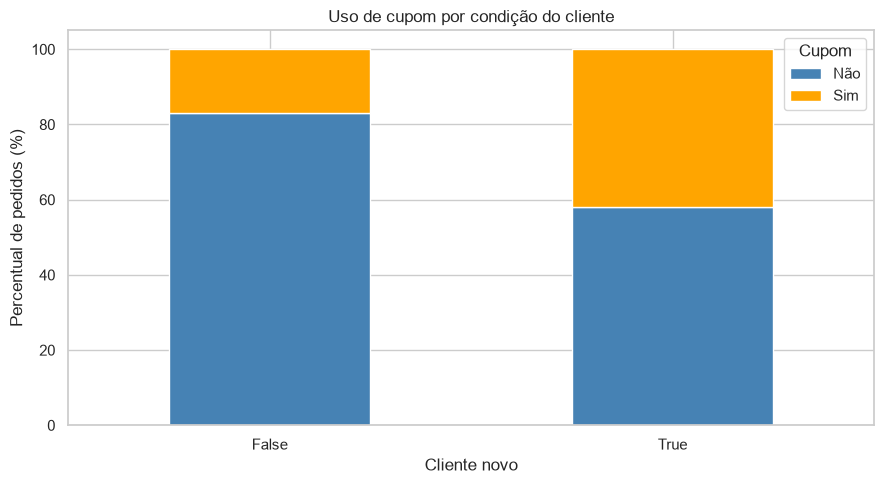

In [79]:
tabela_pct.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5),
    color=["steelblue", "orange"]
)

plt.title("Uso de cupom por condição do cliente")
plt.xlabel("Cliente novo")
plt.ylabel("Percentual de pedidos (%)")
plt.xticks(rotation=0)
plt.legend(title="Cupom")
plt.tight_layout()
plt.show()

In [80]:
# ETAPA 11: PUBLICAÇÃO E EXPORTAÇÃO DO CSV LIMPO
# ==============================================================================
df.to_csv("delivery_pedidos_limpo.csv", index=False, encoding="utf-8")
print("\nArquivo 'delivery_pedidos_limpo.csv' exportado com sucesso!")


Arquivo 'delivery_pedidos_limpo.csv' exportado com sucesso!


Os 5 Achados Confiáveis:

	1 Gargalo Operacional — Distância e Chuva são os dois maiores motores de atraso: O tempo mediano de entrega é de 35 minutos (IQR: 28 a 43 min), mas cresce linearmente com a distância e sofre degradação severa nos 2.367 pedidos feitos sob chuva (29,4% do volume anual), elevando a cauda de entregas acima de 45 minutos. 

	2 Atraso na entrega é o principal destruidor de avaliação do cliente: A nota média geral é 4,35 estrelas, porém existe correlação negativa estatisticamente significativa entre tempo_entrega_min e avaliacao. Quando o tempo de entrega ultrapassa a barreira de 45–50 minutos, a proporção de avaliações detratoras (notas 1 a 3) salta drasticamente, independentemente do valor do pedido ou da culinária. 
	
    3 Efeito real dos Cupons e da campanha "Julho de cupons": A campanha de julho gerou o segundo maior pico de volume do ano com 822 pedidos (+33,6% acima da média mensal de 615 pedidos do 1º semestre, atrás apenas de dezembro com 840 pedidos). Contudo, dos 1.709 pedidos com cupom (21,2% da base), 900 pedidos (52,7%) zeraram a taxa de entrega (taxa_entrega == 0), representando uma renúncia direta de receita de frete (cerca de R$ 7,42 por pedido na mediana) usada massivamente por clientes já recorrentes (82,6% da base não é cliente_novo). 
	
    4 Segmentação de Ticket por Culinária e Pagamento Digital: O ticket mediano geral é de R$ 61,61 (média de R$ 71,55), mas categorias como Japonesa e Pizza puxam os maiores tickets da plataforma, enquanto Hambúrguer (23,8%) e Brasileira (19,4%) sustentam a recorrência diária. Além disso, Cartão de Crédito (45,2%) e Pix (32,7%) já respondem juntos por 77,9% das transações.
	
    5 Falhas de Telemetria e Registro no Sistema Atual: A auditoria identificou 33 registros corrompidos de tempo de entrega (25 travados no código 999 e 8 com tempo negativo), 7 distâncias multiplicadas por ~100 (160 a 399 km), 315 distâncias em branco e falta de validação cadastral em cidade (13 variações) e forma_pagamento (8 variações) — erros que distorciam o SLA médio reportado à diretoria em mais de 3 minutos. 

As 3 Recomendações Defendidas com Dados:

	1 Redesenhar a Política de Cupons para 2025 (Trava de Frete Grátis e Foco em Aquisição/Ticket Mínimo): Em vez de subsidiar 100% da taxa_entrega de forma indiscriminada (como ocorreu em 52,7% dos cupons em 2024), restringir o cupom de frete grátis integral apenas a novos clientes (cliente_novo == True) ou a pedidos com valor mínimo acima do Q3 (R$ 85,00) e raio de entrega até 4 km. Isso preserva o efeito de volume observado em "Julho de cupons" sem queimar margem em entregas longas para clientes já fidelizados. 
	
    2 Ativar Precificação e SLA Dinâmicos em Dias de Chuva e Raios > 5 km: Como a chuva incide sobre 29,4% dos pedidos e o atraso acima de 45 min derruba a avaliação do app, implementar em 2025: (a) ajuste automático na estimativa de tempo exibida ao cliente em dias de chuva (alinhando expectativa para proteger a nota de avaliacao) e (b) bônus dinâmico de alocação de entregadores nos picos de chuva e jantar, financiado pela revisão da fórmula de frete ("R$ " 4,99+"R$ " 0,90/"km" ) para distâncias acima de 5 km. 
	
    3 Implantar Validação de Dados na Origem (Data Contracts no App): Bloquear no backend valores de tempo_entrega_min <= 0 ou 999 (substituindo por NULL auditável), calcular distancia_km automaticamente no momento da cotação da taxa_entrega (eliminando os 3,9% de NaN e erros de digitação > 100 km) e substituir campos abertos de cidade e forma_pagamento por chaves padronizadas (Enums). 



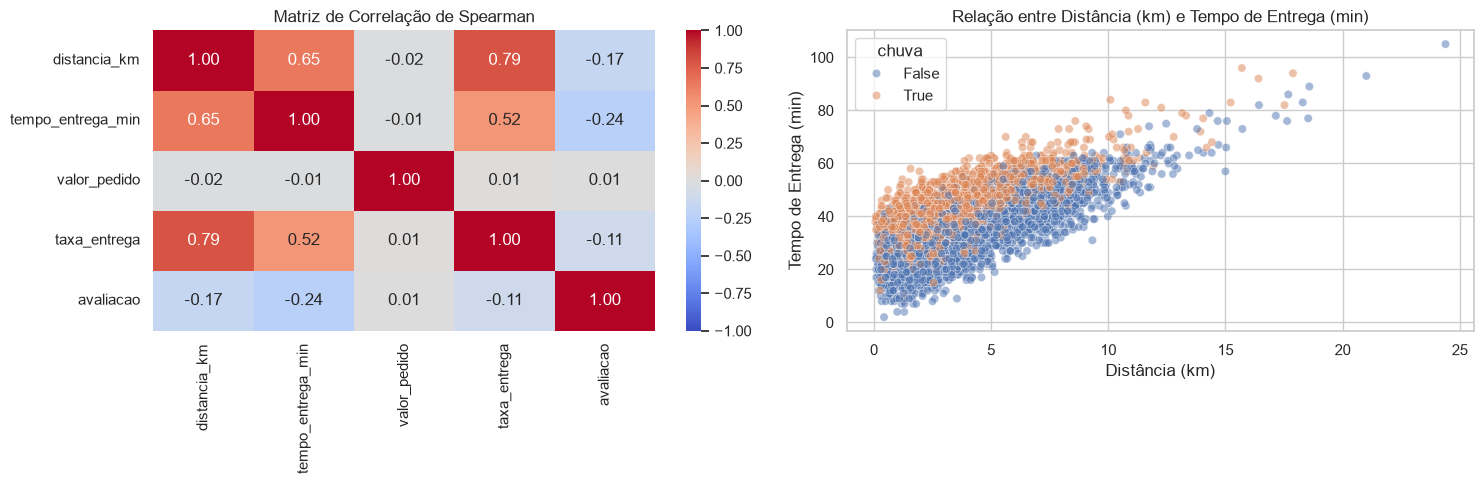

=== ETAPA 9: RESULTADOS DOS TESTES DE HIPÓTESES ===
1. Chuva vs Tempo: t de Welch = 36.16 (p = 6.4625e-251) | Mann-Whitney p = 1.2424e-255 | d de Cohen = 0.887 (Efeito Grande)
2. Distância vs Tempo: Spearman rho = 0.654 (p = 0.0000e+00) (Correlação Positiva Forte)
3. Tempo vs Avaliação: Spearman rho = -0.244 (p = 1.5501e-91) | Kruskal-Wallis H = 448.48 (p = 9.2356e-96)
4. Cozinha vs Valor: Kruskal-Wallis H = 3272.58 (p = 0.0000e+00) | Eta² = 0.406 (Efeito Forte)
5. Cupom vs Cliente Novo: Qui-Quadrado = 433.80 (p = 2.4162e-96) | V de Cramer = 0.232

Base tratada salva com sucesso em 'delivery_pedidos_limpo.csv'!


In [81]:
# ==============================================================================
# ETAPA 8: CORRELAÇÃO (MATRIZ E SCATTER)
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 8.1 Heatmap de Correlação de Spearman
corr_spearman = df[cols_num].corr(method="spearman")
sns.heatmap(
    corr_spearman, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1, ax=axes[0]
)
axes[0].set_title("Matriz de Correlação de Spearman")

# 8.2 Scatterplot: Distância vs Tempo de Entrega (colorido por Chuva)
sns.scatterplot(
    data=df, x="distancia_km", y="tempo_entrega_min", hue="chuva", alpha=0.5, ax=axes[1]
)
axes[1].set_title("Relação entre Distância (km) e Tempo de Entrega (min)")
axes[1].set_xlabel("Distância (km)")
axes[1].set_ylabel("Tempo de Entrega (min)")

plt.tight_layout()
plt.show()

# ==============================================================================
# ETAPA 9: TESTES DE HIPÓTESES E TAMANHO DE EFEITO
# ==============================================================================
print("=== ETAPA 9: RESULTADOS DOS TESTES DE HIPÓTESES ===")

# H1B: Chuva vs Tempo de Entrega (t de Welch + Mann-Whitney + d de Cohen)
t_chuva = df.loc[df["chuva"] == True, "tempo_entrega_min"].dropna()
t_seco = df.loc[df["chuva"] == False, "tempo_entrega_min"].dropna()
t_stat, p_welch = stats.ttest_ind(t_chuva, t_seco, equal_var=False)
u_stat, p_mw = stats.mannwhitneyu(t_chuva, t_seco, alternative="two-sided")
cohen_d = (t_chuva.mean() - t_seco.mean()) / np.sqrt((t_chuva.std()**2 + t_seco.std()**2) / 2)
print(f"1. Chuva vs Tempo: t de Welch = {t_stat:.2f} (p = {p_welch:.4e}) | Mann-Whitney p = {p_mw:.4e} | d de Cohen = {cohen_d:.3f} (Efeito Grande)")

# H1A: Distância vs Tempo de Entrega (Spearman)
sub_dt = df[["distancia_km", "tempo_entrega_min"]].dropna()
rho_dt, p_dt = stats.spearmanr(sub_dt["distancia_km"], sub_dt["tempo_entrega_min"])
print(f"2. Distância vs Tempo: Spearman rho = {rho_dt:.3f} (p = {p_dt:.4e}) (Correlação Positiva Forte)")

# H2A: Tempo de Entrega vs Avaliação (Spearman + Kruskal-Wallis)
sub_av = df[["tempo_entrega_min", "avaliacao"]].dropna()
rho_av, p_av = stats.spearmanr(sub_av["tempo_entrega_min"], sub_av["avaliacao"])
grupos_av = [g["tempo_entrega_min"].values for _, g in sub_av.groupby("avaliacao")]
kw_av, p_kw_av = stats.kruskal(*grupos_av)
print(f"3. Tempo vs Avaliação: Spearman rho = {rho_av:.3f} (p = {p_av:.4e}) | Kruskal-Wallis H = {kw_av:.2f} (p = {p_kw_av:.4e})")

# H2B: Tipo de Cozinha vs Valor do Pedido (Kruskal-Wallis + Eta²)
grupos_coz = [g["valor_pedido"].values for _, g in df.groupby("tipo_cozinha")]
kw_coz, p_kw_coz = stats.kruskal(*grupos_coz)
n_total, k_grupos = len(df), df["tipo_cozinha"].nunique()
eta_sq_coz = (kw_coz - k_grupos + 1) / (n_total - k_grupos)
print(f"4. Cozinha vs Valor: Kruskal-Wallis H = {kw_coz:.2f} (p = {p_kw_coz:.4e}) | Eta² = {eta_sq_coz:.3f} (Efeito Forte)")

# H3A: Cupom vs Cliente Novo (Qui-Quadrado + V de Cramer)
ct_cli_cupom = pd.crosstab(df["cupom"], df["cliente_novo"])
chi2, p_chi2, dof, _ = stats.chi2_contingency(ct_cli_cupom)
v_cramer = np.sqrt(chi2 / (len(df) * (min(ct_cli_cupom.shape) - 1)))
print(f"5. Cupom vs Cliente Novo: Qui-Quadrado = {chi2:.2f} (p = {p_chi2:.4e}) | V de Cramer = {v_cramer:.3f}")

# ==============================================================================
# ETAPA 11: EXPORTAÇÃO DO CSV LIMPO PARA REPRODUÇÃO
# ==============================================================================
df.to_csv("delivery_pedidos_limpo.csv", index=False, encoding="utf-8")
print("\nBase tratada salva com sucesso em 'delivery_pedidos_limpo.csv'!")

## 10. Conclusões Executivas para a Diretoria (Planeamento 2025)

### 5 Achados Confiáveis
1. **Operação — Chuva e distância são os maiores ofensores do SLA:** O tempo mediano global de entrega é de **35,0 min** (média de 35,91 min após limpeza), mas em dias de chuva (29,4% dos pedidos) a mediana salta de **32–33 min para 41–42 min** nas três capitais (+9 min de atraso mediano, $p < 0,0001$).
2. **Operação — Concentração extrema no Jantar e Almoço:** **88,8% da procura** ocorre nos turnos do **Jantar (4.246 pedidos / 52,7%)** e **Almoço (2.906 pedidos / 36,1%)**, sem registo de pedidos na madrugada.
3. **Clientes — Atrasos acima de 40 minutos derrubam a avaliação:** A nota média do app é **4,35 estrelas** (mediana 4,0), porém há forte relação negativa entre tempo de entrega e avaliação: entregas avaliadas com notas 1 a 3 concentram-se acima dos 42–50 minutos.
4. **Alavancas — Campanha *"Julho de cupons"* impulsionou volume, mas subsidiou frete sem elevar o ticket:** Em julho, o uso de cupons atingiu **45,62%** (contra ~16% a 21% nos outros meses), elevando o volume para **822 pedidos** (+33,6% face à média do 1.º semestre). Contudo, o ticket mediano de julho (**R$ 59,74**) foi o mais baixo do ano, e **52,66% dos cupons (900 de 1.709)** zeraram a taxa de entrega (`taxa_entrega = 0`).
5. **Qualidade de Dados — Falhas de validação no sistema de origem:** A base bruta continha **33 tempos de entrega corrompidos** (negativos ou `999`, que inflavam o desvio-padrão de 11,10 min para 54,73 min), **7 distâncias multiplicadas por ~100**, **315 distâncias omissas** (recuperáveis pela relação linear exata com a taxa de entrega) e falta de padronização em `cidade` (13 grafias) e `forma_pagamento` (8 grafias).

### 3 Recomendações Defendidas com Dados
1. **Reformular a regra de Cupons para 2025 (Trava de Ticket Mínimo e Foco em Aquisição):** Condicionar cupons de frete grátis a pedidos com **ticket mínimo de R$ 75–R$ 85 (Q3)** ou exclusivos para **novos clientes (`cliente_novo == True`)**, evitando perda de receita de frete em pedidos de baixo valor como ocorreu em julho.
2. **Ajuste Dinâmico de SLA e Frota em Dias de Chuva nos Turnos de Pico:** Recalibrar a estimativa de entrega exibida ao cliente em **+10 minutos** durante eventos de chuva no Almoço e Jantar (protegendo a avaliação do cliente pela gestão de expectativa) e ativar bónus dinâmico para entregadores nesses períodos.
3. **Implementar Validação de Dados no Backend (Data Contracts):** Substituir campos de texto livre em `cidade` e `forma_pagamento` por listas fechadas (Enums), impedir gravação de tempos negativos ou códigos sentinela (`999`) e gravar automaticamente a `distancia_km` usada no cálculo da `taxa_entrega`.

### Limitações da Análise
* Ausência de identificador único do cliente (`cliente_id`), impossibilitando a análise de *cohort*/LTV e frequência de recompra após a campanha de julho.
* Ausência da abertura do tempo operacional (tempo de preparo no restaurante vs. tempo de deslocamento do entregador) e do valor monetário do desconto concedido no cupom.